# Cell-cycle gene expression in lung adenocarcinoma (TCGA-LUAD)
**Computing Bioinformatics – Group Project**



Shawn James Kuria - 158657

Charles Murage - 165948

Timothy Munyiri Kimani - 166095

Savayi Chelsea - 150765

Erika Diang'a - 168661

Nyokabi Priscillah Njoroge - 169532


## 1. Research question and objectives

**Research question.** Do lung adenocarcinoma (LUAD) tumours differ from matched adjacent normal lung tissue in the expression of cell-cycle genes, and can the expression of these genes alone classify a sample as tumour or normal?

**Objectives**
1. Acquire, document and quality-control TCGA-LUAD RNA-seq expression and clinical data from UCSC Xena.
2. Test for differential expression of cell-cycle genes between tumour and matched normal samples, using paired tests with Benjamini–Hochberg FDR correction, at both the gene and the gene-set level.
3. Interpret the results biologically using pathway/GO enrichment and a STRING protein-interaction network.
4. Build machine-learning classifiers of tumour vs normal and evaluate them against dummy baselines and against random gene sets of the same size.

**Hypothesis.** Cell-cycle genes are upregulated in tumours, reflecting increased proliferation, and more strongly than genes in general.

* H0 (gene level): for a given cell-cycle gene, the median paired tumour–normal difference is zero.
* H0 (self-contained set test): the average cell-cycle expression score does not differ between tumour and matched normal.
* H0 (competitive set test): cell-cycle genes are no more upregulated than randomly chosen genes of the same set size.

**Dataset.** TCGA-LUAD gene expression (Illumina HiSeq, 576 samples) plus the clinical matrix, from the UCSC Xena TCGA hub.

In [1]:
# ---- Setup: libraries, reproducibility, plotting style --------------------
import os, io, re, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import networkx as nx
import requests

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.dummy import DummyClassifier
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.model_selection import StratifiedGroupKFold, cross_validate, cross_val_predict
from sklearn.metrics import (make_scorer, matthews_corrcoef, f1_score, roc_auc_score,
                             balanced_accuracy_score, confusion_matrix, ConfusionMatrixDisplay,
                             RocCurveDisplay, classification_report)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED); random.seed(SEED)
rng = np.random.default_rng(SEED)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 110, "axes.titleweight": "bold"})
COL = {"Tumour": "#C0392B", "Normal": "#2E86C1"}

DATA_DIR = os.environ.get("LUAD_DATA_DIR", "data")
RES_DIR = "results"
os.makedirs(DATA_DIR, exist_ok=True); os.makedirs(RES_DIR, exist_ok=True)

try:
    display
except NameError:          # running outside Jupyter/Colab
    def display(x): print(x.to_string() if hasattr(x, "to_string") else x)

pd.set_option("display.width", 160); pd.set_option("display.max_columns", 30)
print("numpy", np.__version__, "| pandas", pd.__version__, "| scipy", stats.__name__)

numpy 2.4.6 | pandas 2.2.3 | scipy scipy.stats


## 2. Data acquisition

**Source.** UCSC Xena, *TCGA hub* (https://xenabrowser.net/datapages/?cohort=TCGA%20Lung%20Adenocarcinoma%20(LUAD)), cohort *TCGA Lung Adenocarcinoma (LUAD)*. The data were generated by The Cancer Genome Atlas and processed by the TCGA/UCSC pipelines.

| File | Xena dataset ID | What it contains |
|---|---|---|
| HiSeqV2.gz | TCGA.LUAD.sampleMap/HiSeqV2 | Gene-level expression, Illumina HiSeq 2000 RNA-seq. Rows = ~20,500 genes (HUGO symbols); columns = 576 TCGA sample barcodes. Values = **log2(RSEM normalised count + 1)**, already normalised across samples by the TCGA pipeline. |
| LUAD_clinicalMatrix.tsv | TCGA.LUAD.sampleMap/LUAD_clinicalMatrix | One row per sample barcode, ~150 phenotype/clinical columns (sample type, sex, age, stage, smoking, survival, …). |

**TCGA barcode.** TCGA-05-4244-01A : characters 1–12 identify the **patient**; characters 14–15 are the **sample type code** (`01` primary solid tumour, `02` recurrent tumour, `11` solid tissue normal). Matched pairs are patients that have both a `01` and an `11` sample.

The code below downloads both files (it tries the current and the legacy Xena download host) and caches them in " data/ ", so the notebook runs top to bottom in Colab with no manual steps.

In [2]:
XENA_HOSTS = ["https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/",
              "https://tcga.xenahubs.net/download/"]
FILES = {
    "expression": ("TCGA.LUAD.sampleMap/HiSeqV2.gz", "HiSeqV2.gz"),
    "clinical":   ("TCGA.LUAD.sampleMap/LUAD_clinicalMatrix", "LUAD_clinicalMatrix.tsv"),
}

def download(key):
    dataset, local = FILES[key]
    path = os.path.join(DATA_DIR, local)
    if os.path.exists(path) and os.path.getsize(path) > 10_000:
        print(f"[cached] {path} ({os.path.getsize(path)/1e6:.1f} MB)")
        return path
    for host in XENA_HOSTS:
        for name in (dataset.replace("/", "%2F"), dataset):
            url = host + name
            try:
                r = requests.get(url, timeout=180)
                if r.status_code == 200 and len(r.content) > 10_000:
                    with open(path, "wb") as fh:
                        fh.write(r.content)
                    print(f"[downloaded] {url} -> {path} ({len(r.content)/1e6:.1f} MB)")
                    return path
                print(f"  {url}: HTTP {r.status_code}")
            except Exception as e:
                print(f"  {url}: {type(e).__name__}")
    raise RuntimeError(f"Could not download {dataset}; download it from xenabrowser.net into {DATA_DIR}/{local}")

expr_path = download("expression")
clin_path = download("clinical")

expr_raw = pd.read_csv(expr_path, sep="\t", index_col=0)
clin = pd.read_csv(clin_path, sep="\t", index_col=0, low_memory=False)
expr_raw.index.name = "gene"

print("\nExpression matrix:", expr_raw.shape, "(genes x samples)")
print("Clinical matrix:  ", clin.shape, "(samples x variables)")
display(expr_raw.iloc[:5, :5])

[downloaded] https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/TCGA.LUAD.sampleMap%2FHiSeqV2.gz -> data/HiSeqV2.gz (30.9 MB)
[downloaded] https://tcga-xena-hub.s3.us-east-1.amazonaws.com/download/TCGA.LUAD.sampleMap%2FLUAD_clinicalMatrix -> data/LUAD_clinicalMatrix.tsv (0.7 MB)

Expression matrix: (20530, 576) (genes x samples)
Clinical matrix:   (706, 147) (samples x variables)


,TCGA-69-7978-01,TCGA-62-8399-01,TCGA-78-7539-01,TCGA-50-5931-11,TCGA-73-4658-01
gene,,,,,
ARHGEF10L,9.9898,10.4257,9.6264,8.6835,9.2078
HIF3A,4.2598,11.6239,9.1362,9.4824,5.0288
RNF17,0.4181,0.0000,1.1231,0.8221,0.0000
RNF10,10.3657,11.5489,11.6692,11.7341,11.6209
RNF11,11.1718,11.0200,10.4679,11.6787,11.3414


In [3]:
# ---- Describe every file and the variables we use -------------------------
vals = expr_raw.values
print("Expression values: min %.2f, median %.2f, max %.2f, missing %d"
      % (np.nanmin(vals), np.nanmedian(vals), np.nanmax(vals), np.isnan(vals).sum()))
print("Range 0 to ~20 is consistent with log2(normalised count + 1).")

expr_dict = pd.DataFrame({
    "variable": ["row index (gene)", "column (sample barcode)", "cell value"],
    "type": ["string (HUGO symbol)", "string (TCGA barcode)", "float"],
    "description": ["Gene symbol", "TCGA-TSS-Patient-SampleType; chars 1-12 = patient, 14-15 = sample type",
                    "log2(RSEM normalised count + 1)"],
    "n": [expr_raw.shape[0], expr_raw.shape[1], expr_raw.size]})
display(expr_dict)

KEY_CLIN = {
    "_PATIENT": "Patient barcode (first 12 characters)",
    "sample_type": "Primary Tumor / Solid Tissue Normal / Recurrent Tumor",
    "gender": "Reported sex",
    "age_at_initial_pathologic_diagnosis": "Age in years at diagnosis",
    "pathologic_stage": "AJCC pathologic stage",
    "tobacco_smoking_history": "Smoking category (1 = lifelong non-smoker ... 5)",
    "vital_status": "LIVING / DECEASED",
    "days_to_death": "Overall survival time (deceased)",
    "days_to_last_followup": "Follow-up time (censored)",
}
rows = []
for c, desc in KEY_CLIN.items():
    if c in clin.columns:
        s = clin[c]
        ex = ", ".join(map(str, s.dropna().unique()[:4]))
        rows.append([c, desc, str(s.dtype), s.notna().sum(), s.nunique(), ex])
clin_dict = pd.DataFrame(rows, columns=["variable", "description", "dtype", "non-missing", "unique", "examples"])
display(clin_dict)
print(f"All {clin.shape[1]} clinical columns are listed in results/clinical_columns.csv")
pd.Series(clin.columns, name="column").to_csv(f"{RES_DIR}/clinical_columns.csv", index=False)

Expression values: min 0.00, median 7.69, max 20.45, missing 0
Range 0 to ~20 is consistent with log2(normalised count + 1).


,variable,type,description,n
0,row index (gene),string (HUGO symbol),Gene symbol,20530
1,column (sample barcode),string (TCGA barcode),TCGA-TSS-Patient-SampleType; chars 1-12 = pati...,576
2,cell value,float,log2(RSEM normalised count + 1),11825280


,variable,description,dtype,non-missing,unique,examples
0,_PATIENT,Patient barcode (first 12 characters),object,706,584,"TCGA-05-4244, TCGA-05-4249, TCGA-05-4250, TCGA..."
1,sample_type,Primary Tumor / Solid Tissue Normal / Recurren...,object,643,4,"Primary Tumor, Solid Tissue Normal, Recurrent ..."
2,gender,Reported sex,object,642,2,"MALE, FEMALE"
3,age_at_initial_pathologic_diagnosis,Age in years at diagnosis,float64,623,52,"70.0, 67.0, 79.0, 68.0"
4,pathologic_stage,AJCC pathologic stage,object,641,10,"Stage IV, Stage IB, Stage IIIA, Stage IA"
5,tobacco_smoking_history,Smoking category (1 = lifelong non-smoker ... 5),float64,622,5,"4.0, 3.0, 2.0, 1.0"
6,vital_status,LIVING / DECEASED,object,642,2,"LIVING, DECEASED"
7,days_to_death,Overall survival time (deceased),float64,240,176,"121.0, 0.0, 303.0, 731.0"
8,days_to_last_followup,Follow-up time (censored),float64,480,334,"0.0, 1523.0, 607.0, 426.0"


All 147 clinical columns are listed in results/clinical_columns.csv


## 3. Preprocessing and quality control

Steps, each logged with before/after counts:
1. Remove duplicated genes / samples and genes with missing values.
2. Update outdated gene symbols for cell-cycle genes (the Xena file uses 2011-era HUGO symbols, e.g. `CDC2` for **CDK1**).
3. Annotate samples from the barcode, cross-check with the clinical `sample_type`, keep primary tumour (`01`) and solid tissue normal (`11`), one sample per patient per type.
4. Filter lowly expressed genes (log2 expression > 1 in at least 20% of samples) and constant genes.
5. **Biological sanity checks** that must hold if the data are correct: lung-lineage markers (SFTPC, SFTPB, NKX2-1, NAPSA) highly expressed; expression-inferred sex (XIST vs RPS4Y1) agrees with reported sex; the proliferation marker MKI67 higher in tumour.
6. Sample-level outlier screen (correlation with other samples) and construction of matched tumour–normal pairs.

In [5]:
qc_log = []
def log(step, df):
    qc_log.append({"step": step, "genes": df.shape[0], "samples": df.shape[1]})

expr = expr_raw.copy()
log("raw", expr)

n_dup_g, n_dup_s = expr.index.duplicated().sum(), expr.columns.duplicated().sum()
expr = expr.loc[~expr.index.duplicated(keep="first"), ~expr.columns.duplicated(keep="first")]
n_na_genes = expr.isna().any(axis=1).sum()
expr = expr.dropna(axis=0, how="any")
log("remove duplicates + genes with NA", expr)
print(f"duplicated genes: {n_dup_g}, duplicated samples: {n_dup_s}, genes with NA removed: {n_na_genes}")

# Outdated -> current HGNC symbols for cell-cycle genes
ALIASES = {"CDK1": ["CDC2"], "ORC1": ["ORC1L"], "ORC2": ["ORC2L"], "ORC3": ["ORC3L"], "ORC4": ["ORC4L"],
           "ORC5": ["ORC5L"], "ORC6": ["ORC6L"], "SMC1A": ["SMC1L1"], "SMC1B": ["SMC1L2"],
           "WEE2": ["WEE1B"], "CDC45": ["CDC45L"], "ZBTB17": ["ZNF151"], "NKX2-1": ["TITF1"]}
renamed = {}
for new, olds in ALIASES.items():
    if new in expr.index:
        continue
    for old in olds:
        if old in expr.index:
            renamed[old] = new; break
expr = expr.rename(index=renamed)
print("Symbols updated:", renamed if renamed else "none needed")

duplicated genes: 0, duplicated samples: 0, genes with NA removed: 0
Symbols updated: {'ORC1L': 'ORC1', 'ORC2L': 'ORC2', 'ORC3L': 'ORC3', 'ORC4L': 'ORC4', 'ORC5L': 'ORC5', 'ORC6L': 'ORC6'}


In [6]:
# ---- Sample annotation from barcodes --------------------------------------
meta = pd.DataFrame(index=pd.Index(expr.columns, name="sample"))
meta["patient"] = meta.index.str[:12]
meta["type_code"] = meta.index.str[13:15]
CODE_MAP = {"01": "Primary Tumour", "02": "Recurrent Tumour", "06": "Metastatic", "11": "Solid Tissue Normal"}
meta["sample_type"] = meta["type_code"].map(CODE_MAP).fillna("Other")
print("All samples by barcode type:")
display(meta["sample_type"].value_counts().to_frame("n"))

# cross-check with the clinical matrix
if "sample_type" in clin.columns:
    cl = clin["sample_type"].reindex(meta.index)
    norm = cl.str.lower().str.replace("primary tumor", "primary tumour").str.replace("recurrent tumor", "recurrent tumour")
    agree = (norm == meta["sample_type"].str.lower())
    print(f"Barcode type agrees with clinical sample_type for {agree.sum()}/{cl.notna().sum()} samples with clinical annotation")

# keep 01 + 11, one per patient per type
keep = meta[meta["type_code"].isin(["01", "11"])].sort_index()
n_extra = keep.duplicated(["patient", "type_code"]).sum()
keep = keep[~keep.duplicated(["patient", "type_code"], keep="first")].copy()
print(f"Removed {(meta.shape[0]-keep.shape[0])-n_extra} non-01/11 samples and {n_extra} repeat aliquots of the same patient/type")
meta = keep
meta["label"] = (meta["type_code"] == "01").astype(int)
meta["group"] = np.where(meta["label"] == 1, "Tumour", "Normal")
expr = expr[meta.index]
log("keep primary tumour + normal (1 per patient/type)", expr)

# attach clinical data at patient level
pat_col = clin["_PATIENT"] if "_PATIENT" in clin.columns else pd.Series(clin.index.str[:12], index=clin.index)
clin_pat = clin.groupby(pat_col.values).first()
for c in ["gender", "age_at_initial_pathologic_diagnosis", "pathologic_stage", "tobacco_smoking_history"]:
    if c in clin_pat.columns:
        meta[c] = meta["patient"].map(clin_pat[c])
display(meta.groupby("group").size().to_frame("samples"))

All samples by barcode type:


,n
sample_type,
Primary Tumour,515
Solid Tissue Normal,59
Recurrent Tumour,2


Barcode type agrees with clinical sample_type for 575/576 samples with clinical annotation
Removed 2 non-01/11 samples and 0 repeat aliquots of the same patient/type


,samples
group,
Normal,59
Tumour,515


Genes failing expression filter: 2586, constant genes: 333


,step,genes,samples
0,raw,20530,576
1,remove duplicates + genes with NA,20530,576
2,keep primary tumour + normal (1 per patient/type),20530,574
3,filter: log2 expr > 1.0 in >= 20% samples,17944,574


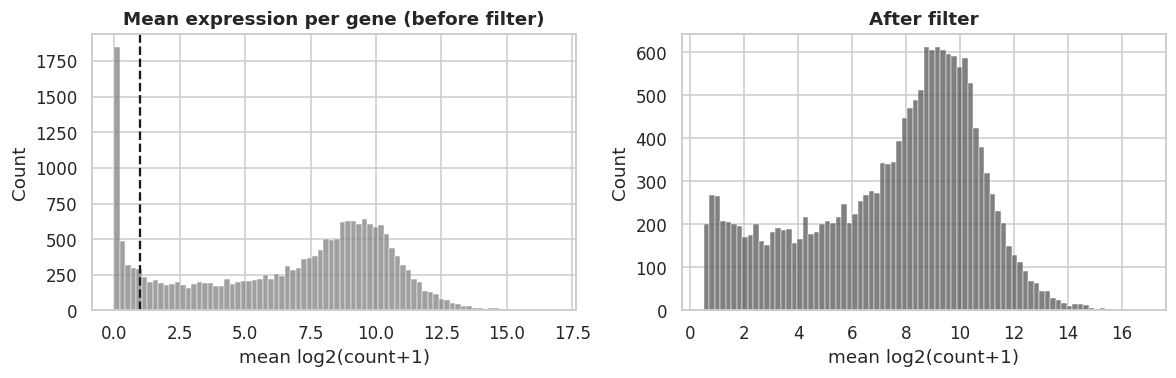

In [7]:
# ---- Gene filtering --------------------------------------------------------
MIN_EXPR, MIN_FRAC = 1.0, 0.20
expressed = (expr > MIN_EXPR).mean(axis=1) >= MIN_FRAC
nonconst = expr.std(axis=1) > 0
print(f"Genes failing expression filter: {(~expressed).sum()}, constant genes: {(~nonconst).sum()}")
expr_all = expr.copy()                    # unfiltered (used for sanity checks on any gene)
expr = expr[expressed & nonconst]
log(f"filter: log2 expr > {MIN_EXPR} in >= {int(MIN_FRAC*100)}% samples", expr)

qc_table = pd.DataFrame(qc_log)
display(qc_table)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
sns.histplot(expr_all.mean(axis=1), bins=80, ax=ax[0], color="grey")
ax[0].axvline(MIN_EXPR, ls="--", c="k"); ax[0].set(title="Mean expression per gene (before filter)", xlabel="mean log2(count+1)")
sns.histplot(expr.mean(axis=1), bins=80, ax=ax[1], color="#555")
ax[1].set(title="After filter", xlabel="mean log2(count+1)")
plt.tight_layout(); plt.show()

Lung lineage markers should sit near the top of the expression distribution in every sample:


,median percentile (Normal),median percentile (Tumour)
gene,,
SFTPC,1.000,0.943
SFTPB,1.000,1.000
NKX2-1,0.932,0.939
NAPSA,0.999,0.997
GAPDH,0.994,0.999
ACTB,1.000,1.000


MKI67 mean log2: tumour 10.22, normal 7.37
Inferred sex matches reported sex in 566/574 samples


,patient,group,gender,sex_inferred
sample,,,,
TCGA-44-7669-01,TCGA-44-7669,Tumour,MALE,FEMALE
TCGA-44-8119-01,TCGA-44-8119,Tumour,MALE,FEMALE
TCGA-49-4505-01,TCGA-49-4505,Tumour,FEMALE,MALE
TCGA-55-6969-01,TCGA-55-6969,Tumour,MALE,FEMALE
TCGA-55-8094-01,TCGA-55-8094,Tumour,MALE,FEMALE
TCGA-55-A490-01,TCGA-55-A490,Tumour,MALE,FEMALE
TCGA-62-A470-01,TCGA-62-A470,Tumour,MALE,FEMALE
TCGA-NJ-A55R-01,TCGA-NJ-A55R,Tumour,MALE,FEMALE


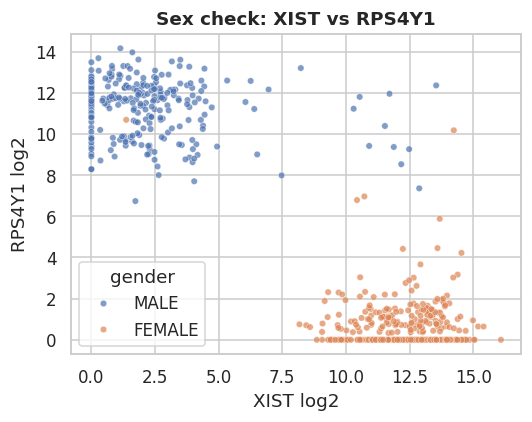

{'MKI67 tumour - normal (log2)': np.float64(2.85), 'sex mismatches': 8}


In [8]:
# ---- Biological sanity checks ---------------------------------------------
pct = expr_all.rank(pct=True)          # within-sample percentile of each gene
markers = [g for g in ["SFTPC", "SFTPB", "NKX2-1", "NAPSA", "GAPDH", "ACTB"] if g in pct.index]
mk = pct.loc[markers].T.groupby(meta["group"]).median().T.round(3)
mk.columns = [f"median percentile ({c})" for c in mk.columns]
print("Lung lineage markers should sit near the top of the expression distribution in every sample:")
display(mk)

sanity = {}
if "MKI67" in expr_all.index:
    m = expr_all.loc["MKI67"].groupby(meta["group"]).mean()
    sanity["MKI67 tumour - normal (log2)"] = round(m["Tumour"] - m["Normal"], 2)
    print(f"MKI67 mean log2: tumour {m['Tumour']:.2f}, normal {m['Normal']:.2f}")

if {"XIST", "RPS4Y1"} <= set(expr_all.index) and "gender" in meta:
    meta["sex_inferred"] = np.where(expr_all.loc["RPS4Y1"] > expr_all.loc["XIST"], "MALE", "FEMALE")
    known = meta["gender"].notna()
    mism = meta[known & (meta["gender"].str.upper() != meta["sex_inferred"])]
    sanity["sex mismatches"] = len(mism)
    print(f"Inferred sex matches reported sex in {(known.sum()-len(mism))}/{known.sum()} samples")
    if len(mism): display(mism[["patient", "group", "gender", "sex_inferred"]])
    plt.figure(figsize=(5, 4))
    sns.scatterplot(x=expr_all.loc["XIST"], y=expr_all.loc["RPS4Y1"], hue=meta["gender"], s=18, alpha=.7)
    plt.title("Sex check: XIST vs RPS4Y1"); plt.xlabel("XIST log2"); plt.ylabel("RPS4Y1 log2")
    plt.tight_layout(); plt.show()
print(sanity)

In [9]:
# ---- Sample outlier screen + matched pairs --------------------------------
top_var = expr.var(axis=1).sort_values(ascending=False).index[:2000]
C = np.corrcoef(expr.loc[top_var].T.values)
np.fill_diagonal(C, np.nan)
med_corr = pd.Series(np.nanmedian(C, axis=1), index=expr.columns)
q1, q3 = med_corr.quantile([.25, .75])
outliers = med_corr[med_corr < q1 - 3 * (q3 - q1)]
print(f"Median inter-sample correlation: {med_corr.median():.3f}; outliers (< Q1 - 3*IQR): {len(outliers)}")
if len(outliers):
    display(pd.DataFrame({"median_corr": outliers.round(3), "group": meta.loc[outliers.index, "group"]}))
print("Outliers are reported, not removed: low correlation can be genuine tumour heterogeneity.")

tum = meta[meta.label == 1].reset_index().set_index("patient")["sample"]
nor = meta[meta.label == 0].reset_index().set_index("patient")["sample"]
pairs = sorted(set(tum.index) & set(nor.index))
T = expr[tum[pairs].values]; T.columns = pairs
N = expr[nor[pairs].values]; N.columns = pairs
n_pairs = len(pairs)
print(f"\nTumour samples: {len(tum)}, normal samples: {len(nor)}, matched pairs: {n_pairs}")
print(f"Unpaired normals (patient has no tumour sample in this file): {len(set(nor.index) - set(tum.index))}")

Median inter-sample correlation: 0.568; outliers (< Q1 - 3*IQR): 0
Outliers are reported, not removed: low correlation can be genuine tumour heterogeneity.

Tumour samples: 515, normal samples: 59, matched pairs: 58
Unpaired normals (patient has no tumour sample in this file): 1


### Cell-cycle gene set

The primary gene set is the **KEGG "Cell cycle" pathway (hsa04110)**, downloaded live from the KEGG REST API (a curated copy is used if KEGG cannot be reached). We also define biologically coherent **sub-modules** so that the gene-set tests can show *which parts* of the cycle change: G1/S progression, DNA-replication licensing, G2/M & mitosis, the anaphase-promoting complex, checkpoint kinases, CDK inhibitors/tumour suppressors, cohesin, and the 14-3-3 / TGF-β arm.

In [10]:
KEGG_FALLBACK = '''ABL1 ANAPC1 ANAPC2 ANAPC4 ANAPC5 ANAPC7 ANAPC10 ANAPC11 ANAPC13 ATM ATR BUB1 BUB1B BUB3
CCNA1 CCNA2 CCNB1 CCNB2 CCNB3 CCND1 CCND2 CCND3 CCNE1 CCNE2 CCNH CDC6 CDC7 CDC14A CDC14B CDC16 CDC20
CDC23 CDC25A CDC25B CDC25C CDC27 CDC45 CDK1 CDK2 CDK4 CDK6 CDK7 CDKN1A CDKN1B CDKN1C CDKN2A CDKN2B
CDKN2C CDKN2D CHEK1 CHEK2 CREBBP CUL1 DBF4 E2F1 E2F2 E2F3 E2F4 E2F5 EP300 ESPL1 FZR1 GADD45A GADD45B
GADD45G GSK3B HDAC1 HDAC2 MAD1L1 MAD2L1 MAD2L2 MCM2 MCM3 MCM4 MCM5 MCM6 MCM7 MDM2 MYC ORC1 ORC2 ORC3
ORC4 ORC5 ORC6 PCNA PKMYT1 PLK1 PRKDC PTTG1 PTTG2 RAD21 RB1 RBL1 RBL2 RBX1 SFN SKP1 SKP2 SMAD2 SMAD3
SMAD4 SMC1A SMC1B SMC3 STAG1 STAG2 TFDP1 TFDP2 TGFB1 TGFB2 TGFB3 TP53 TTK WEE1 WEE2 YWHAB YWHAE YWHAG
YWHAH YWHAQ YWHAZ ZBTB17'''.split()

def kegg_pathway_genes(pid="hsa04110"):
    txt = requests.get(f"https://rest.kegg.jp/get/{pid}", timeout=30).text
    genes, in_gene = [], False
    for line in txt.splitlines():
        if line.startswith("GENE"):
            in_gene, line = True, line[4:]
        elif line[:1].strip():
            in_gene = False
        if in_gene:
            parts = line.strip().split(None, 1)
            if len(parts) == 2:
                genes.append(parts[1].split(";")[0].strip())
    return genes

try:
    KEGG_CC = kegg_pathway_genes()
    assert len(KEGG_CC) > 80
    cc_source = f"KEGG REST hsa04110 (retrieved {time.strftime('%Y-%m-%d')})"
except Exception as e:
    KEGG_CC = KEGG_FALLBACK
    cc_source = f"curated KEGG hsa04110 list (KEGG unreachable: {type(e).__name__})"
KEGG_CC = sorted(set(KEGG_CC))
print(f"Cell-cycle genes: {len(KEGG_CC)} from {cc_source}")

MODULES = {
    "G1/S progression": "CCND1 CCND2 CCND3 CDK4 CDK6 CCNE1 CCNE2 CDK2 E2F1 E2F2 E2F3 TFDP1 TFDP2 CDC25A MYC SKP2",
    "Replication licensing": "MCM2 MCM3 MCM4 MCM5 MCM6 MCM7 ORC1 ORC2 ORC3 ORC4 ORC5 ORC6 CDC6 CDC45 CDC7 DBF4 PCNA",
    "G2/M & mitosis": "CCNA2 CCNB1 CCNB2 CDK1 CDC25B CDC25C PLK1 PKMYT1 WEE1 CDC20 ESPL1 PTTG1 BUB1 BUB1B BUB3 MAD2L1 MAD1L1 TTK CDC14A CDC14B",
    "APC/C": "ANAPC1 ANAPC2 ANAPC4 ANAPC5 ANAPC7 ANAPC10 ANAPC11 ANAPC13 CDC16 CDC23 CDC27 FZR1",
    "Checkpoint kinases": "ATM ATR CHEK1 CHEK2 PRKDC MDM2 TP53",
    "CDK inhibitors / suppressors": "CDKN1A CDKN1B CDKN1C CDKN2A CDKN2B CDKN2C CDKN2D RB1 RBL1 RBL2 GADD45A GADD45B GADD45G SFN",
    "Cohesin": "SMC1A SMC1B SMC3 STAG1 STAG2 RAD21",
    "14-3-3 & TGF-beta arm": "YWHAB YWHAE YWHAG YWHAH YWHAQ YWHAZ TGFB1 TGFB2 TGFB3 SMAD2 SMAD3 SMAD4 GSK3B",
}
MODULES = {k: v.split() for k, v in MODULES.items()}

cc_genes = [g for g in KEGG_CC if g in expr.index]
missing = [g for g in KEGG_CC if g not in expr.index]
print(f"Present after filtering: {len(cc_genes)}; absent or lowly expressed: {len(missing)} -> {missing}")
GENE_SETS = {"KEGG cell cycle (all)": cc_genes}
GENE_SETS.update({k: [g for g in v if g in expr.index] for k, v in MODULES.items()})
display(pd.Series({k: len(v) for k, v in GENE_SETS.items()}, name="genes in data").to_frame())

Cell-cycle genes: 158 from KEGG REST hsa04110 (retrieved 2026-11-10)
Present after filtering: 152; absent or lowly expressed: 6 -> ['ANAPC15', 'KNL1', 'MAU2', 'SGO1', 'TICRR', 'WAPL']


,genes in data
KEGG cell cycle (all),152
G1/S progression,16
Replication licensing,17
G2/M & mitosis,20
APC/C,12
Checkpoint kinases,7
CDK inhibitors / suppressors,14
Cohesin,6
14-3-3 & TGF-beta arm,13


**Interpretation (QC).** _To be completed from the outputs above._

## 4. Exploratory data analysis

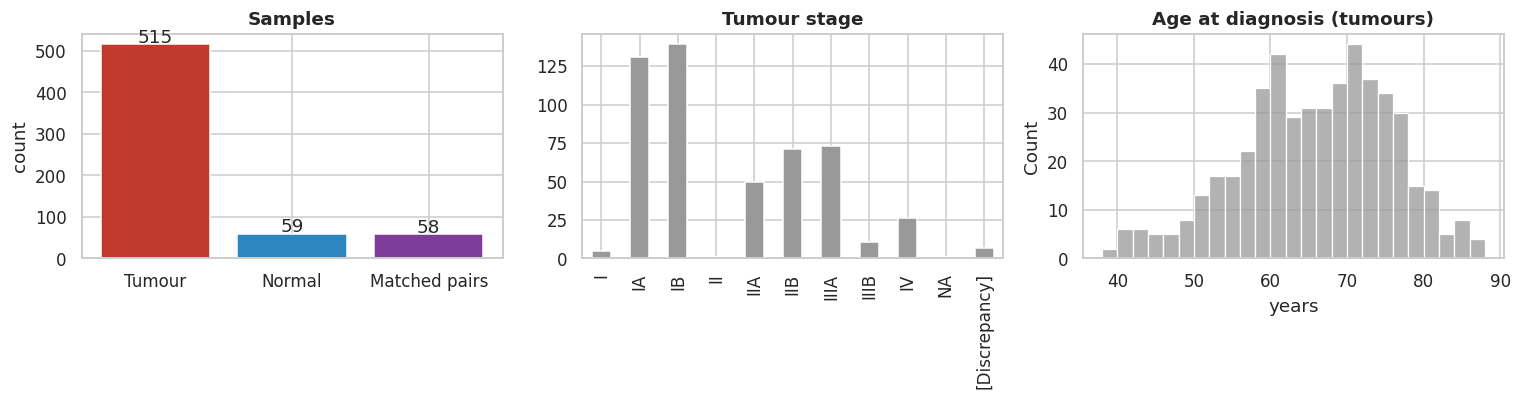

In [11]:
# 4.1 Cohort composition
fig, ax = plt.subplots(1, 3, figsize=(14, 3.8))
gc = meta["group"].value_counts()
ax[0].bar(gc.index, gc.values, color=[COL[g] for g in gc.index])
ax[0].bar(["Matched pairs"], [n_pairs], color="#7D3C98")
for i, v in enumerate(list(gc.values) + [n_pairs]): ax[0].text(i, v + 5, v, ha="center")
ax[0].set(title="Samples", ylabel="count")
if "pathologic_stage" in meta:
    st = meta.loc[meta.label == 1, "pathologic_stage"].fillna("NA").str.replace("Stage ", "")
    st.value_counts().sort_index().plot.bar(ax=ax[1], color="#999"); ax[1].set(title="Tumour stage", xlabel="")
if "age_at_initial_pathologic_diagnosis" in meta:
    sns.histplot(pd.to_numeric(meta.loc[meta.label == 1, "age_at_initial_pathologic_diagnosis"], errors="coerce"),
                 bins=25, ax=ax[2], color="#999"); ax[2].set(title="Age at diagnosis (tumours)", xlabel="years")
plt.tight_layout(); plt.show()

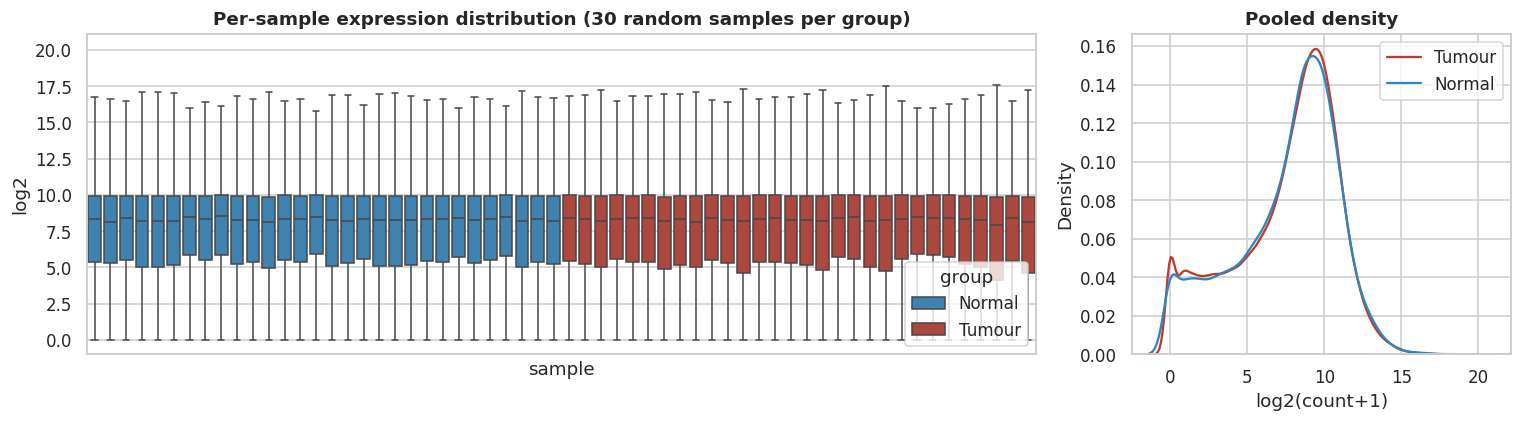

In [12]:
# 4.2 Expression distributions: are samples comparably normalised?
sub = pd.concat([d.sample(min(len(d), 30), random_state=SEED) for _, d in meta.groupby("group")])
long = expr[sub.index].melt(var_name="sample", value_name="log2").merge(sub[["group"]], left_on="sample", right_index=True)
fig, ax = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [3, 1.2]})
order = sub.sort_values("group").index
sns.boxplot(data=long, x="sample", y="log2", hue="group", order=order, palette=COL, fliersize=0, ax=ax[0], dodge=False)
ax[0].set_xticks([]); ax[0].set(title="Per-sample expression distribution (30 random samples per group)", xlabel="sample")
for g in ["Tumour", "Normal"]:
    sns.kdeplot(expr.loc[:, meta.group == g].values.ravel()[::50], ax=ax[1], color=COL[g], label=g)
ax[1].set(title="Pooled density", xlabel="log2(count+1)"); ax[1].legend()
plt.tight_layout(); plt.show()

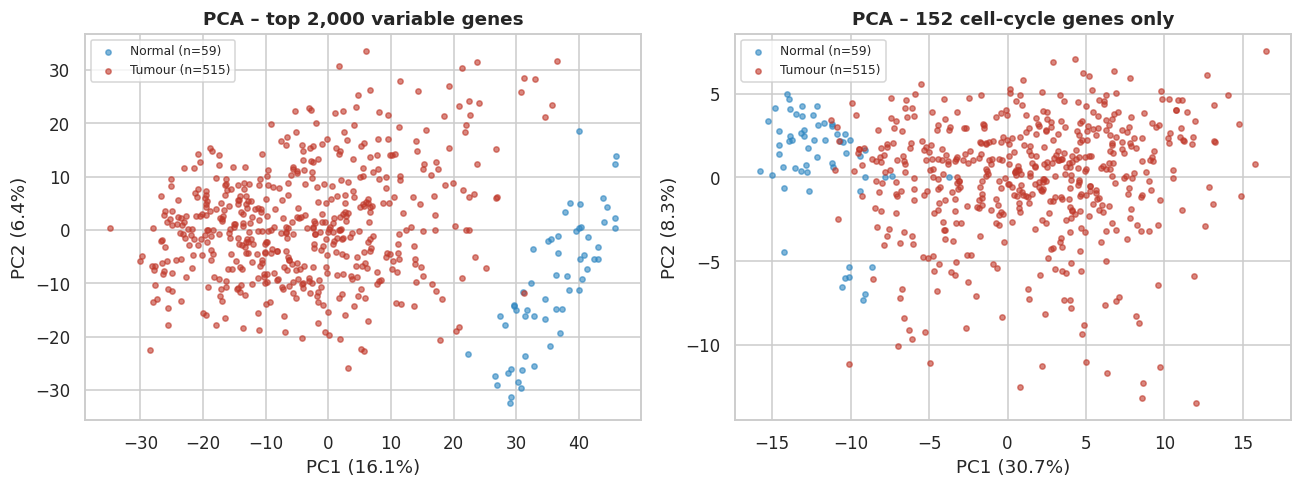

In [13]:
# 4.3 PCA: all informative genes vs cell-cycle genes only
def pca_plot(X, title, ax):
    Z = StandardScaler().fit_transform(X.T.values)
    p = PCA(n_components=2, random_state=SEED).fit(Z)
    pcs = p.transform(Z)
    for g in ["Normal", "Tumour"]:
        m = (meta.loc[X.columns, "group"] == g).values
        ax.scatter(pcs[m, 0], pcs[m, 1], s=12, alpha=.6, c=COL[g], label=f"{g} (n={m.sum()})")
    ax.set(title=title, xlabel=f"PC1 ({p.explained_variance_ratio_[0]*100:.1f}%)",
           ylabel=f"PC2 ({p.explained_variance_ratio_[1]*100:.1f}%)")
    ax.legend(fontsize=8)
    return pcs

fig, ax = plt.subplots(1, 2, figsize=(12, 4.6))
pca_plot(expr.loc[top_var], "PCA – top 2,000 variable genes", ax[0])
pcs_cc = pca_plot(expr.loc[cc_genes], f"PCA – {len(cc_genes)} cell-cycle genes only", ax[1])
plt.tight_layout(); plt.show()

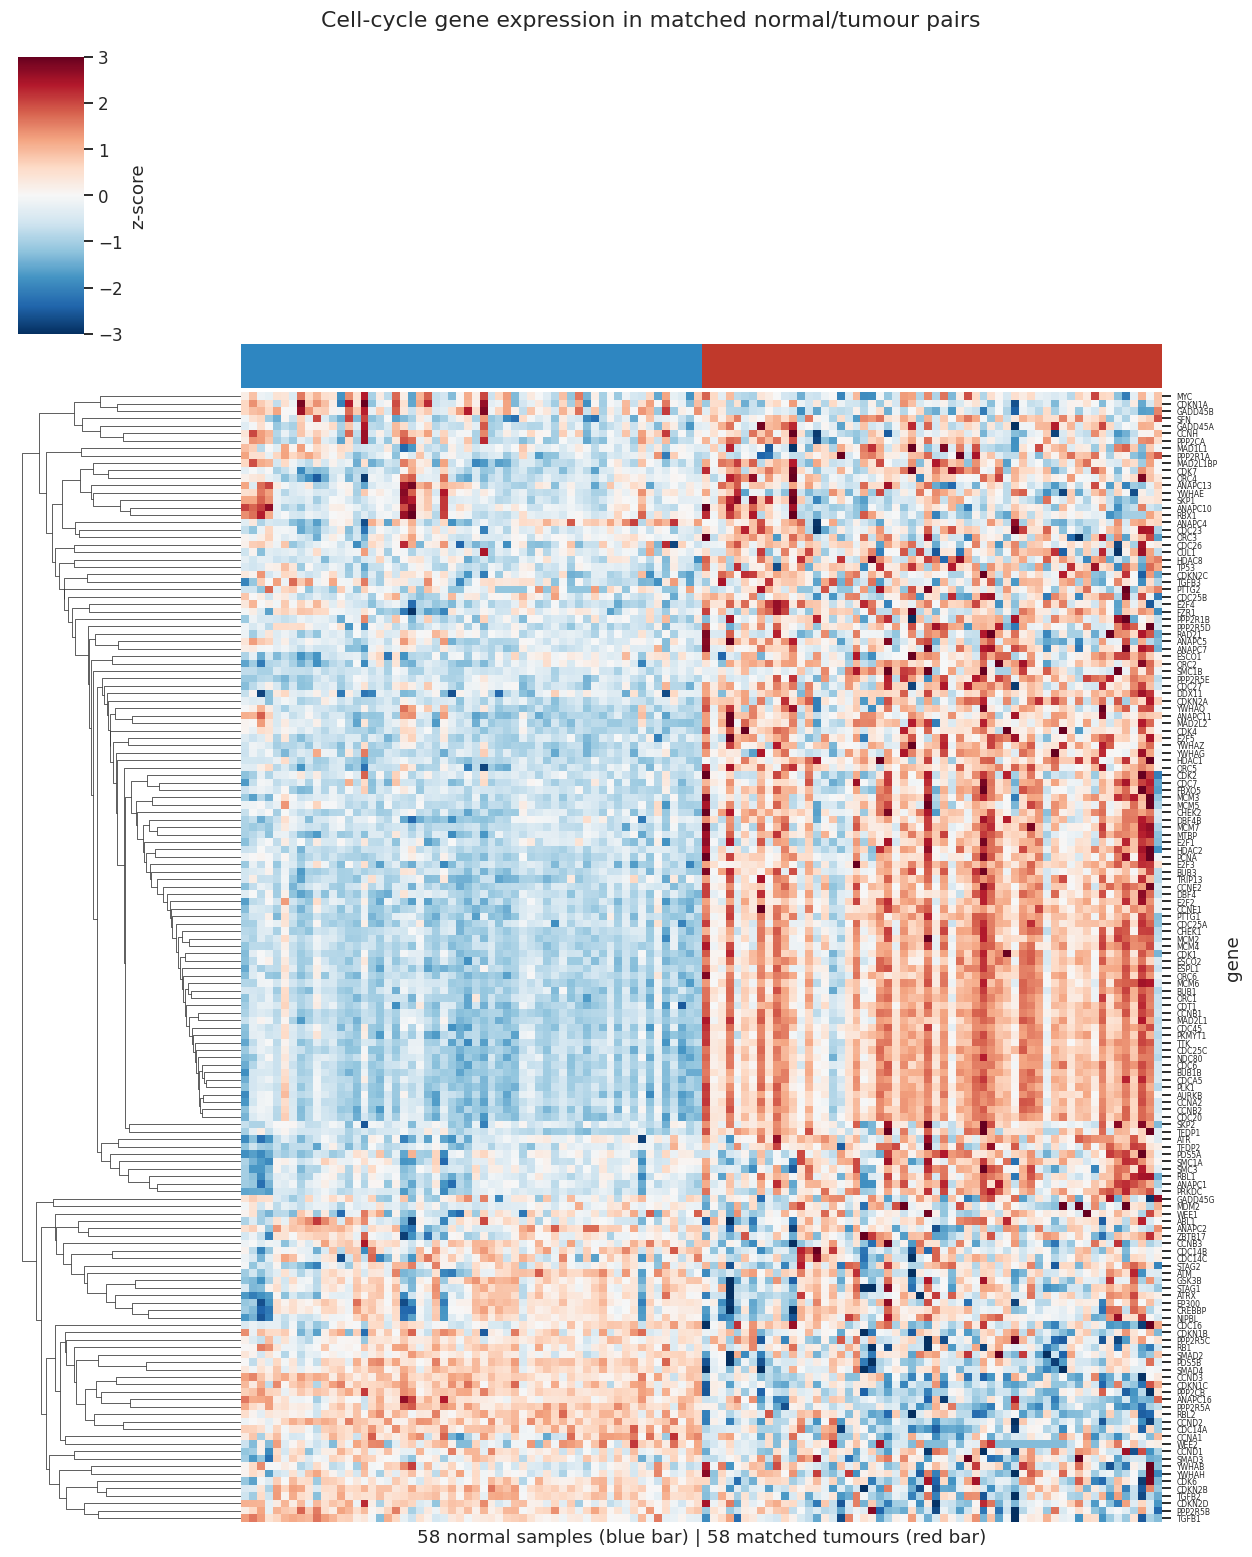

In [14]:
# 4.4 Cell-cycle genes across matched pairs (z-scored per gene)
Zp = pd.concat([N, T], axis=1, keys=["Normal", "Tumour"]).loc[cc_genes]
Zp = Zp.sub(Zp.mean(1), axis=0).div(Zp.std(1), axis=0)
col_colors = [COL[g] for g in Zp.columns.get_level_values(0)]
cg = sns.clustermap(Zp, col_cluster=False, row_cluster=True, cmap="RdBu_r", center=0, vmin=-3, vmax=3,
                    col_colors=col_colors, xticklabels=False, yticklabels=True, figsize=(12, 14),
                    cbar_kws={"label": "z-score"})
cg.ax_heatmap.set_yticklabels(cg.ax_heatmap.get_yticklabels(), fontsize=5)
cg.ax_heatmap.set_xlabel(f"{n_pairs} normal samples (blue bar) | {n_pairs} matched tumours (red bar)")
cg.fig.suptitle("Cell-cycle gene expression in matched normal/tumour pairs", y=1.01)
plt.show()

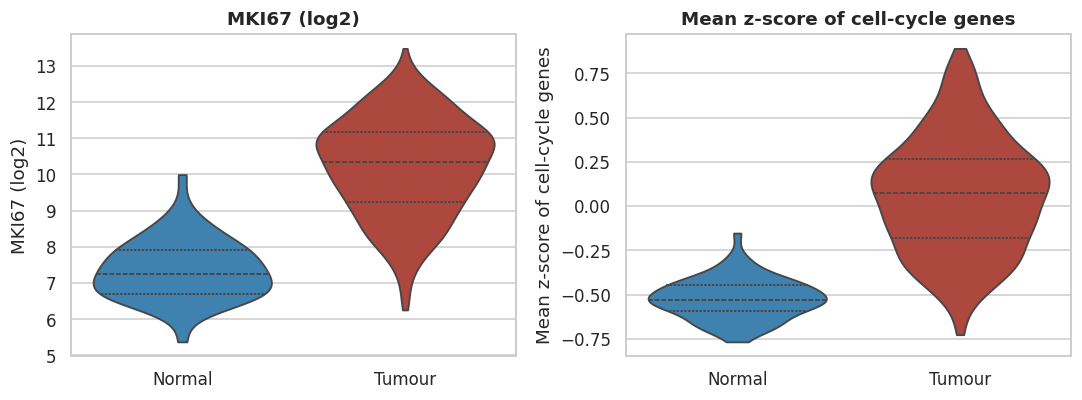

In [15]:
# 4.5 Proliferation marker and a cell-cycle score across all samples
cc_score_all = expr.loc[cc_genes].sub(expr.loc[cc_genes].mean(1), axis=0).div(expr.loc[cc_genes].std(1), axis=0).mean(0)
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8))
for a, (vals, name) in zip(ax, [(expr_all.loc["MKI67"] if "MKI67" in expr_all.index else cc_score_all, "MKI67 (log2)"),
                               (cc_score_all, "Mean z-score of cell-cycle genes")]):
    sns.violinplot(x=meta["group"], y=vals, palette=COL, ax=a, inner="quartile", cut=0, order=["Normal", "Tumour"])
    a.set(title=name, xlabel="", ylabel=name)
plt.tight_layout(); plt.show()

**Interpretation (EDA).** _To be completed from the outputs above._

## 5. Core analysis: differential expression

### 5.1 Gene level (paired)
For every gene we compute the within-patient difference *d = tumour − normal* (log2 scale, so the mean of *d* is the **log2 fold change**). The primary test is the **Wilcoxon signed-rank test** (paired, non-parametric, robust to outliers); the paired *t*-test and the effect size *d<sub>z</sub>* = mean(d)/sd(d) are reported alongside.

Benjamini–Hochberg FDR is applied (i) **within the cell-cycle family** (the confirmatory test of our hypothesis) and (ii) **genome-wide** (all filtered genes, used for the volcano plot, enrichment and the competitive comparison).

A gene is called differentially expressed if **FDR < 0.05 and |log2FC| ≥ 1** (at least a two-fold change).

In [16]:
def bh_fdr(p):
    p = np.asarray(p, float); n = len(p)
    order = np.argsort(p)
    q = p[order] * n / np.arange(1, n + 1)
    q = np.minimum.accumulate(q[::-1])[::-1]
    out = np.empty(n); out[order] = np.minimum(q, 1)
    return out

# self-check against statsmodels when it is installed (Colab has it)
try:
    from statsmodels.stats.multitest import multipletests
    _p = rng.uniform(size=500)
    assert np.allclose(bh_fdr(_p), multipletests(_p, method="fdr_bh")[1])
    print("BH implementation matches statsmodels")
except ImportError:
    print("statsmodels not installed; using own BH implementation")

FDR, LFC = 0.05, 1.0
D = T.values - N.values
t_stat, p_t = stats.ttest_rel(T.values, N.values, axis=1)
p_w = stats.wilcoxon(D, axis=1).pvalue

de = pd.DataFrame({
    "mean_tumour": T.mean(1), "mean_normal": N.mean(1),
    "log2FC": D.mean(1), "median_diff": np.median(D, 1),
    "frac_pairs_up": (D > 0).mean(1), "dz": D.mean(1) / D.std(1, ddof=1),
    "t": t_stat, "p_ttest": p_t, "p_wilcoxon": p_w}, index=T.index)
n_untestable = de["p_wilcoxon"].isna().sum() + de["t"].isna().sum()
de = de.dropna(subset=["p_wilcoxon", "t"])   # genes with identical values in every pair cannot be tested
print(f"Genes dropped as untestable (zero paired variance): {n_untestable}")
de["fdr_genome"] = bh_fdr(de["p_wilcoxon"])
de["cell_cycle"] = de.index.isin(cc_genes)

def call(fdr, lfc):
    return np.where((fdr < FDR) & (lfc >= LFC), "Up", np.where((fdr < FDR) & (lfc <= -LFC), "Down", "NS"))
de["call_genome"] = call(de["fdr_genome"], de["log2FC"])

cc_genes = [g for g in cc_genes if g in de.index]
GENE_SETS = {k: [g for g in v if g in de.index] for k, v in GENE_SETS.items()}
cc_de = de[de.cell_cycle].copy()
cc_de["fdr_cc"] = bh_fdr(cc_de["p_wilcoxon"])
cc_de["call"] = call(cc_de["fdr_cc"], cc_de["log2FC"])
cc_de["_order"] = cc_de["call"].map({"Up": 0, "Down": 1, "NS": 2})
cc_de = cc_de.sort_values(["_order", "log2FC"], ascending=[True, False]).drop(columns="_order")
cc_de.round(5).to_csv(f"{RES_DIR}/cell_cycle_DE.csv")
de.round(5).to_csv(f"{RES_DIR}/genome_wide_DE.csv")

print(f"{n_pairs} matched pairs, {len(de)} genes tested genome-wide, {len(cc_de)} cell-cycle genes")
print("Cell-cycle calls (FDR within family < 0.05, |log2FC| >= 1):", cc_de["call"].value_counts().to_dict())
print("Cell-cycle genes significant at FDR < 0.05 regardless of fold change:",
      (cc_de.fdr_cc < FDR).sum(), "| of which up:", ((cc_de.fdr_cc < FDR) & (cc_de.log2FC > 0)).sum())
print("Genome-wide calls:", de["call_genome"].value_counts().to_dict())
cols = ["mean_normal", "mean_tumour", "log2FC", "frac_pairs_up", "dz", "p_wilcoxon", "fdr_cc", "fdr_genome", "call"]
display(cc_de[cols].head(25).style.format({"p_wilcoxon": "{:.2e}", "fdr_cc": "{:.2e}", "fdr_genome": "{:.2e}",
                                           "mean_normal": "{:.2f}", "mean_tumour": "{:.2f}", "log2FC": "{:.2f}",
                                           "frac_pairs_up": "{:.2f}", "dz": "{:.2f}"}) if hasattr(cc_de, "style") else cc_de[cols].head(25))
print("Down-regulated / non-significant cell-cycle genes:")
display(cc_de.loc[cc_de.call != "Up", cols].round(4))

BH implementation matches statsmodels
Genes dropped as untestable (zero paired variance): 0
58 matched pairs, 17944 genes tested genome-wide, 152 cell-cycle genes
Cell-cycle calls (FDR within family < 0.05, |log2FC| >= 1): {'NS': 98, 'Up': 47, 'Down': 7}
Cell-cycle genes significant at FDR < 0.05 regardless of fold change: 121 | of which up: 95
Genome-wide calls: {'NS': 13750, 'Down': 2472, 'Up': 1722}


,mean_normal,mean_tumour,log2FC,frac_pairs_up,dz,p_wilcoxon,fdr_cc,fdr_genome,call
gene,,,,,,,,,
CDC25C,2.13,6.01,3.88,1.00,2.29,3.51e-11,3.04e-10,1.22e-09,Up
CDC20,5.12,8.98,3.86,1.00,2.13,3.51e-11,3.04e-10,1.22e-09,Up
CDC45,3.31,6.98,3.67,1.00,2.01,3.51e-11,3.04e-10,1.22e-09,Up
BUB1B,4.29,7.94,3.64,1.00,2.15,3.51e-11,3.04e-10,1.22e-09,Up
TTK,3.74,7.17,3.43,0.98,1.75,4.55e-11,3.04e-10,1.22e-09,Up
AURKB,3.87,7.25,3.38,0.98,1.89,3.69e-11,3.04e-10,1.22e-09,Up
PLK1,5.33,8.67,3.34,1.00,2.10,3.51e-11,3.04e-10,1.22e-09,Up
CDC6,5.02,8.30,3.28,1.00,2.09,3.51e-11,3.04e-10,1.22e-09,Up
NDC80,4.09,7.30,3.21,0.97,1.87,5.61e-11,3.09e-10,1.22e-09,Up


Down-regulated / non-significant cell-cycle genes:


,mean_normal,mean_tumour,log2FC,frac_pairs_up,dz,p_wilcoxon,fdr_cc,fdr_genome,call
gene,,,,,,,,,
CDKN1C,9.2722,8.1404,-1.1318,0.1207,-1.1116,0.0000,0.0000,0.0000,Down
CDC14A,8.3663,7.1084,-1.2579,0.1379,-1.1476,0.0000,0.0000,0.0000,Down
TGFB2,9.7199,8.3629,-1.3569,0.2759,-0.7785,0.0000,0.0000,0.0000,Down
GADD45B,11.5504,10.1790,-1.3714,0.1379,-1.1050,0.0000,0.0000,0.0000,Down
CCND2,10.9311,9.5364,-1.3946,0.0690,-1.4048,0.0000,0.0000,0.0000,Down
...,...,...,...,...,...,...,...,...,...
TGFB1,11.0587,10.5366,-0.5220,0.2759,-0.6103,0.0000,0.0001,0.0001,NS
CCNB3,4.1036,3.4635,-0.6401,0.3276,-0.4627,0.0004,0.0005,0.0007,NS
PPP2CB,11.6414,10.8231,-0.8183,0.0345,-1.3579,0.0000,0.0000,0.0000,NS


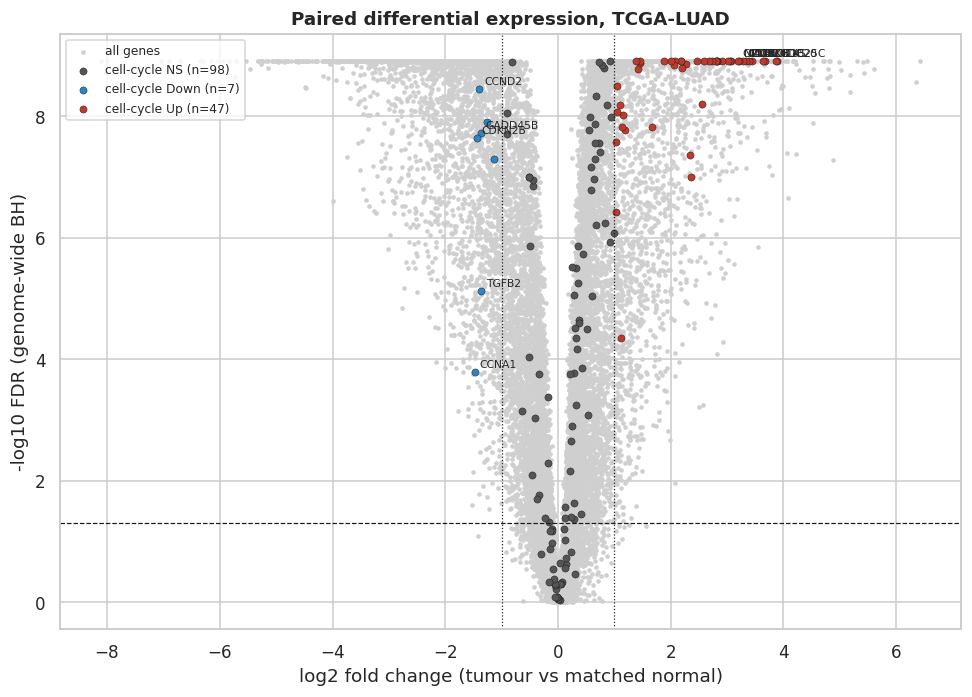

In [17]:
# 5.2 Volcano plot (genome-wide), cell-cycle genes highlighted
fig, ax = plt.subplots(figsize=(9, 6.5))
y = -np.log10(de["fdr_genome"].clip(lower=1e-300))
ax.scatter(de["log2FC"], y, s=4, c="#cfcfcf", label="all genes", rasterized=True)
cmap = {"Up": COL["Tumour"], "Down": COL["Normal"], "NS": "#555"}
for c in ["NS", "Down", "Up"]:
    m = cc_de["call"] == c
    ax.scatter(cc_de.loc[m, "log2FC"], -np.log10(cc_de.loc[m, "fdr_genome"]), s=22, c=cmap[c],
               edgecolor="k", lw=.3, label=f"cell-cycle {c} (n={m.sum()})")
lab = pd.concat([cc_de.nlargest(10, "log2FC"), cc_de.nsmallest(5, "log2FC")])
for g, r in lab.iterrows():
    ax.annotate(g, (r.log2FC, -np.log10(r.fdr_genome)), fontsize=7, xytext=(3, 3), textcoords="offset points")
ax.axhline(-np.log10(FDR), ls="--", c="k", lw=.8); ax.axvline(LFC, ls=":", c="k", lw=.8); ax.axvline(-LFC, ls=":", c="k", lw=.8)
ax.set(xlabel="log2 fold change (tumour vs matched normal)", ylabel="-log10 FDR (genome-wide BH)",
       title="Paired differential expression, TCGA-LUAD")
ax.legend(fontsize=8, loc="upper left"); plt.tight_layout(); plt.show()

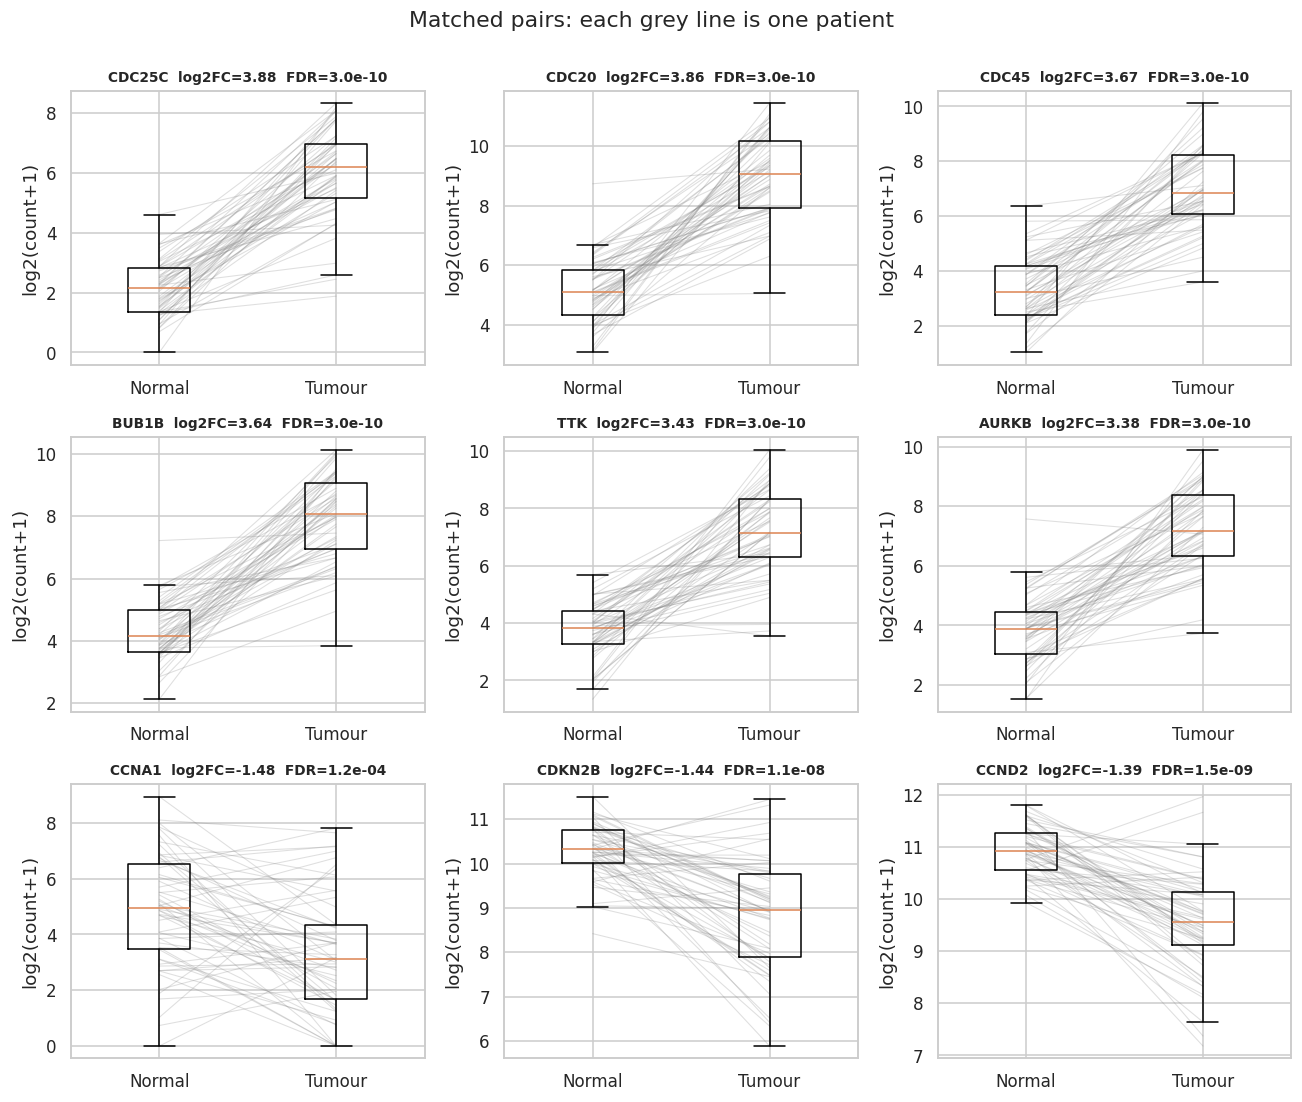

In [18]:
# 5.3 Paired trajectories for the strongest cell-cycle genes
show = list(cc_de.nlargest(6, "log2FC").index) + list(cc_de.nsmallest(3, "log2FC").index)
fig, axes = plt.subplots(3, 3, figsize=(12, 10))
for ax, g in zip(axes.ravel(), show):
    for p in pairs:
        ax.plot([0, 1], [N.at[g, p], T.at[g, p]], c="grey", alpha=.25, lw=.7)
    ax.boxplot([N.loc[g], T.loc[g]], positions=[0, 1], widths=.35, showfliers=False)
    r = cc_de.loc[g]
    ax.set_xticks([0, 1]); ax.set_xticklabels(["Normal", "Tumour"])
    ax.set_title(f"{g}  log2FC={r.log2FC:.2f}  FDR={r.fdr_cc:.1e}", fontsize=9)
    ax.set_ylabel("log2(count+1)")
plt.suptitle("Matched pairs: each grey line is one patient", y=1.0); plt.tight_layout(); plt.show()

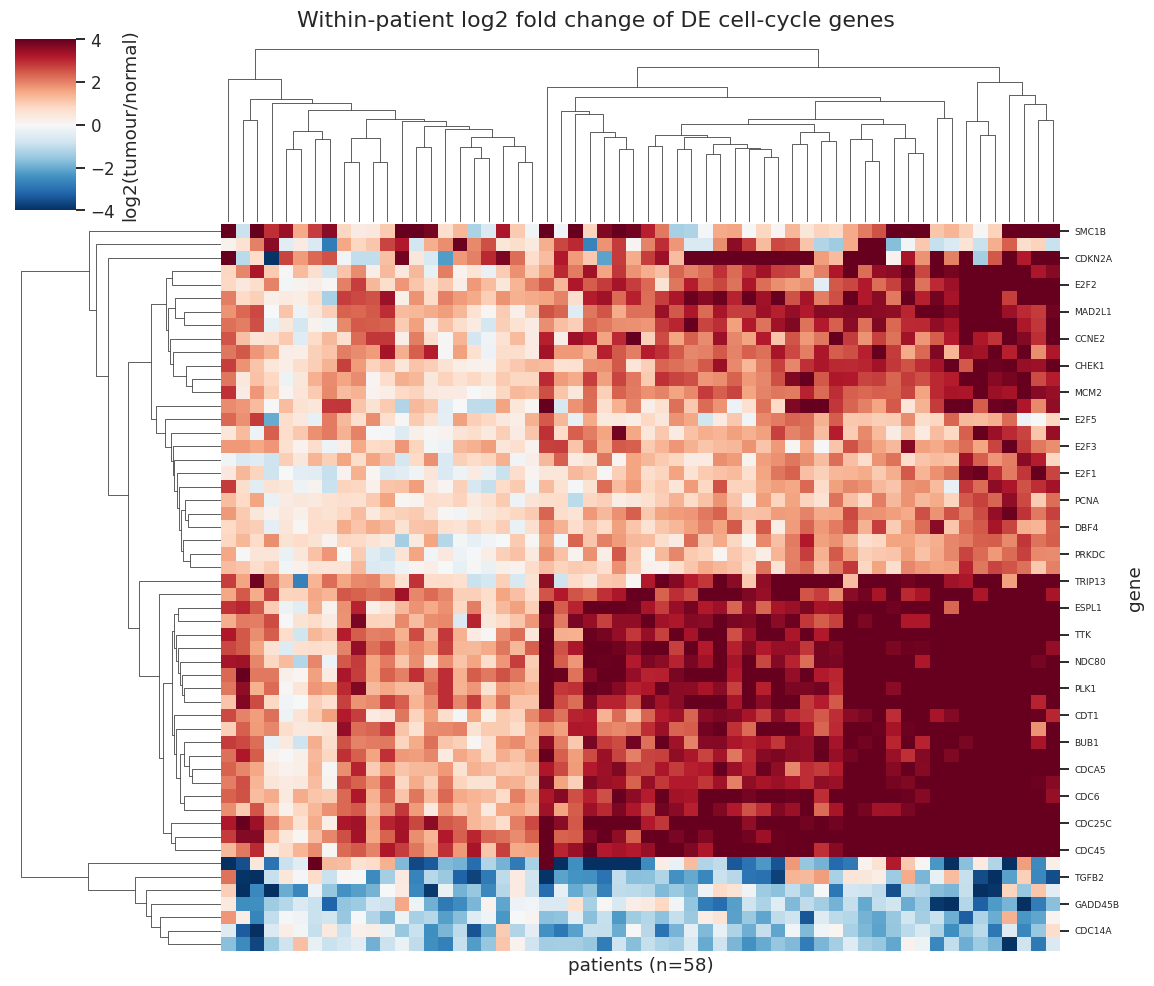

In [19]:
# 5.4 Per-patient fold changes of significant cell-cycle genes: is the change consistent across patients?
sig = cc_de.index[cc_de["call"] != "NS"]
if len(sig) >= 2:
    Dcc = pd.DataFrame(D, index=T.index, columns=pairs).loc[sig]
    cg = sns.clustermap(Dcc, cmap="RdBu_r", center=0, vmin=-4, vmax=4, xticklabels=False, figsize=(11, max(5, .16 * len(sig))),
                        cbar_kws={"label": "log2(tumour/normal)"})
    cg.ax_heatmap.set_yticklabels(cg.ax_heatmap.get_yticklabels(), fontsize=6)
    cg.ax_heatmap.set_xlabel(f"patients (n={n_pairs})")
    cg.fig.suptitle("Within-patient log2 fold change of DE cell-cycle genes", y=1.01); plt.show()

### 5.5 Gene-set level
Two complementary questions (Goeman & Bühlmann 2007):

* **Self-contained test** – *is the set as a whole changed?* Each sample gets a set score (mean of gene-wise z-scores). We test the paired tumour–normal score difference with a Wilcoxon signed-rank test and with an exact-style **sign-flip permutation** (10,000 random swaps of tumour/normal labels within patients).
* **Competitive test** – *is the set more changed than genes in general?* (the second half of our hypothesis). The mean paired *t*-statistic of the set is compared with **10,000 random gene sets of the same size** drawn from all other expressed genes. A rank-based Mann–Whitney comparison of set vs non-set *t*-statistics and a Fisher test on the proportion of up-regulated genes are reported as well.

BH correction is applied across the gene sets for each test.

In [20]:
Zpair = pd.concat([T, N], axis=1, keys=["T", "N"])
Zpair = Zpair.sub(Zpair.mean(1), axis=0).div(Zpair.std(1), axis=0)
B = 10_000
tvals = de["t"]; all_genes = np.array(de.index)
set_rows, null_store = [], {}
for name, gs in GENE_SETS.items():
    if len(gs) < 3: continue
    s = Zpair.loc[gs].mean(0); dscore = (s["T"] - s["N"]).values
    p_wsr = stats.wilcoxon(dscore).pvalue
    signs = rng.choice([-1, 1], size=(B, len(dscore)))
    null_mean = (signs * dscore).mean(1)
    p_flip = (1 + (np.abs(null_mean) >= abs(dscore.mean())).sum()) / (B + 1)
    # competitive: random sets of equal size from genes outside this set
    bg = np.setdiff1d(all_genes, gs); bg_t = tvals.loc[bg].values
    null_t = np.concatenate([bg_t[np.argpartition(rng.random((1000, len(bg))), len(gs), axis=1)[:, :len(gs)]].mean(1)
                             for _ in range(B // 1000)])   # sampling without replacement, in chunks
    obs_t = tvals.loc[gs].mean()
    null_store[name] = (null_t, obs_t)
    p_comp_up = (1 + (null_t >= obs_t).sum()) / (B + 1)
    p_comp_2s = (1 + (np.abs(null_t - null_t.mean()) >= abs(obs_t - null_t.mean())).sum()) / (B + 1)
    p_mwu = stats.mannwhitneyu(tvals.loc[gs], bg_t, alternative="two-sided").pvalue
    set_rows.append({"gene_set": name, "n_genes": len(gs), "mean_log2FC": de.loc[gs, "log2FC"].mean(),
                     "score_diff_T_minus_N": dscore.mean(), "frac_patients_up": (dscore > 0).mean(),
                     "p_selfcontained_wilcoxon": p_wsr, "p_selfcontained_signflip": p_flip,
                     "mean_t_set": obs_t, "mean_t_random": null_t.mean(),
                     "p_competitive_up": p_comp_up, "p_competitive_2sided": p_comp_2s, "p_mannwhitney": p_mwu})
gset = pd.DataFrame(set_rows).set_index("gene_set")
for c in ["p_selfcontained_wilcoxon", "p_competitive_up", "p_competitive_2sided", "p_mannwhitney"]:
    gset[c.replace("p_", "fdr_")] = bh_fdr(gset[c])
gset.round(5).to_csv(f"{RES_DIR}/gene_set_tests.csv")
display(gset[["n_genes", "mean_log2FC", "frac_patients_up", "fdr_selfcontained_wilcoxon", "p_selfcontained_signflip",
              "mean_t_set", "mean_t_random", "fdr_competitive_up", "fdr_competitive_2sided", "fdr_mannwhitney"]].round(4))

# Fisher test: proportion of up-regulated genes, cell-cycle vs all other genes (genome-wide calls)
cc_up = int(((de.cell_cycle) & (de.call_genome == "Up")).sum()); cc_n = int(de.cell_cycle.sum())
oth_up = int(((~de.cell_cycle) & (de.call_genome == "Up")).sum()); oth_n = int((~de.cell_cycle).sum())
OR, p_fisher = stats.fisher_exact([[cc_up, cc_n - cc_up], [oth_up, oth_n - oth_up]], alternative="greater")
print(f"Up-regulated (genome FDR<0.05, log2FC>=1): cell-cycle {cc_up}/{cc_n} = {cc_up/cc_n:.1%} vs other genes {oth_up}/{oth_n} = {oth_up/oth_n:.1%}; "
      f"odds ratio {OR:.2f}, one-sided Fisher p = {p_fisher:.2e}")

,n_genes,mean_log2FC,frac_patients_up,fdr_selfcontained_wilcoxon,p_selfcontained_signflip,mean_t_set,mean_t_random,fdr_competitive_up,fdr_competitive_2sided,fdr_mannwhitney
gene_set,,,,,,,,,,
KEGG cell cycle (all),152,0.7627,0.9483,0.0000,0.0001,4.7747,0.0484,0.0003,0.0003,0.0000
G1/S progression,16,0.7882,0.9138,0.0000,0.0001,4.9008,0.0618,0.0022,0.0070,0.0090
Replication licensing,17,1.5362,1.0000,0.0000,0.0001,10.6961,0.0710,0.0003,0.0003,0.0000
G2/M & mitosis,20,2.1353,0.9655,0.0000,0.0001,10.7278,0.0575,0.0003,0.0003,0.0000
APC/C,12,0.2020,0.7759,0.0000,0.0001,2.9096,0.0710,0.0873,0.1872,0.1384
Checkpoint kinases,7,0.8005,0.9310,0.0000,0.0001,6.4825,0.1290,0.0058,0.0202,0.0090
CDK inhibitors / suppressors,14,-0.0222,0.3448,0.0011,0.0004,-1.2573,0.0999,0.7859,0.4853,0.4164
Cohesin,6,0.5279,0.6897,0.0003,0.0001,3.0631,0.1292,0.1655,0.3363,0.2264
14-3-3 & TGF-beta arm,13,-0.0416,0.4310,0.9414,0.7493,0.3739,0.0936,0.4960,0.8760,0.8901


Up-regulated (genome FDR<0.05, log2FC>=1): cell-cycle 47/152 = 30.9% vs other genes 1675/17792 = 9.4%; odds ratio 4.31, one-sided Fisher p = 1.58e-13


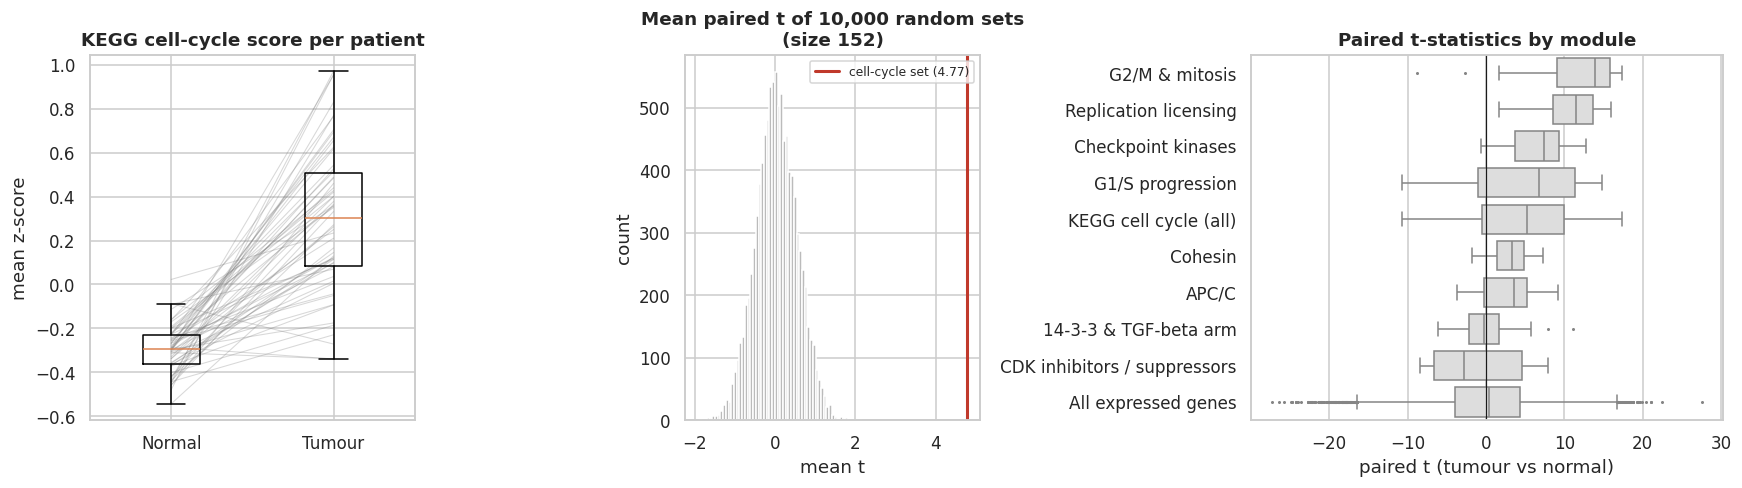

In [21]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4.6), gridspec_kw={"width_ratios": [1.1, 1, 1.6]})
# (a) set score in matched pairs
s = Zpair.loc[cc_genes].mean(0)
for p in pairs: ax[0].plot([0, 1], [s["N"][p], s["T"][p]], c="grey", alpha=.3, lw=.7)
ax[0].boxplot([s["N"], s["T"]], positions=[0, 1], widths=.35, showfliers=False)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["Normal", "Tumour"])
ax[0].set(title="KEGG cell-cycle score per patient", ylabel="mean z-score")
# (b) competitive null
null_t, obs_t = null_store["KEGG cell cycle (all)"]
ax[1].hist(null_t, bins=60, color="#bbb"); ax[1].axvline(obs_t, c=COL["Tumour"], lw=2, label=f"cell-cycle set ({obs_t:.2f})")
ax[1].set(title=f"Mean paired t of {B:,} random sets\n(size {len(cc_genes)})", xlabel="mean t", ylabel="count"); ax[1].legend(fontsize=8)
# (c) per-module t distribution vs background
dfm = pd.concat([pd.DataFrame({"set": k, "t": tvals.loc[v].values}) for k, v in GENE_SETS.items() if len(v) >= 3] +
                [pd.DataFrame({"set": "All expressed genes", "t": tvals.values})], ignore_index=True)
order_sets = list(gset.sort_values("mean_t_set", ascending=False).index) + ["All expressed genes"]
sns.boxplot(data=dfm, y="set", x="t", order=order_sets, ax=ax[2], color="#ddd", fliersize=1)
ax[2].axvline(0, c="k", lw=.8); ax[2].set(title="Paired t-statistics by module", ylabel="", xlabel="paired t (tumour vs normal)")
plt.tight_layout(); plt.show()

**Interpretation (differential expression).** _To be completed from the outputs above._

## 6. Biological interpretation

### 6.1 Enrichment analysis (Enrichr: GO Biological Process, KEGG, Reactome)
To check the hypothesis **without assuming it**, we take the genome-wide top 300 up-regulated genes and top 300 down-regulated genes (FDR < 0.05, |log2FC| ≥ 1, ranked by fold change) and ask which pathways they are enriched for. If tumour up-regulation is dominated by proliferation, cell-cycle terms should rank near the top of the *up* list even though the list was not chosen with cell-cycle genes in mind. We also run enrichment on the significant cell-cycle genes themselves to see which sub-processes drive the change.

The analysis uses the Enrichr web API (Chen et al. 2013; Kuleshov et al. 2016). A local hypergeometric test of the KEGG set against the background of expressed genes is computed regardless, so the conclusion does not depend on the API being available.

In [22]:
ENRICHR = "https://maayanlab.cloud/Enrichr"
LIBS = ["GO_Biological_Process_2023", "KEGG_2021_Human", "Reactome_2022"]

def enrichr(genes, desc, libs=LIBS, top=10):
    r = requests.post(f"{ENRICHR}/addList", files={"list": (None, "\n".join(genes)), "description": (None, desc)}, timeout=60)
    uid = r.json()["userListId"]; out = []
    for lib in libs:
        res = requests.get(f"{ENRICHR}/enrich", params={"userListId": uid, "backgroundType": lib}, timeout=60).json()[lib]
        for row in res[:top]:
            out.append({"library": lib, "term": row[1], "p": row[2], "adj_p": row[6], "combined_score": row[4],
                        "n_overlap": len(row[5]), "genes": ",".join(row[5][:12])})
        time.sleep(0.3)
    return pd.DataFrame(out)

sig_up = de[de.call_genome == "Up"].sort_values("log2FC", ascending=False)
sig_dn = de[de.call_genome == "Down"].sort_values("log2FC")
up300, dn300 = list(sig_up.index[:300]), list(sig_dn.index[:300])
cc_sig = list(cc_de.index[cc_de.call != "NS"])
print(f"Genome-wide up: {len(sig_up)}, down: {len(sig_dn)}; using top {len(up300)} up / {len(dn300)} down")

# local hypergeometric test: are KEGG cell-cycle genes over-represented among the top-300 up genes?
M, K, n_ = len(de), len(cc_genes), len(up300); k = len(set(up300) & set(cc_genes))
p_hyper = stats.hypergeom.sf(k - 1, M, K, n_)
print(f"Cell-cycle genes among top-{n_} up: {k} (expected {n_*K/M:.1f}); fold enrichment {k/(n_*K/M):.1f}, hypergeometric p = {p_hyper:.2e}")
print("Cell-cycle genes among top-300 DOWN:", len(set(dn300) & set(cc_genes)))

enr = {}
for name, gl in [("up", up300), ("down", dn300), ("cell-cycle DE", cc_sig)]:
    if len(gl) < 5: continue
    try:
        enr[name] = enrichr(gl, f"LUAD {name}")
        enr[name].to_csv(f"{RES_DIR}/enrichr_{name.replace(' ', '_')}.csv", index=False)
    except Exception as e:
        print(f"Enrichr unavailable for '{name}' list ({type(e).__name__}); local hypergeometric result above still applies.")
for name, df_ in enr.items():
    print(f"\nTop terms – {name} list")
    display(df_.groupby("library").head(5)[["library", "term", "adj_p", "n_overlap", "genes"]]
            .assign(adj_p=lambda x: x.adj_p.map("{:.1e}".format)))

Genome-wide up: 1722, down: 2472; using top 300 up / 300 down
Cell-cycle genes among top-300 up: 20 (expected 2.5); fold enrichment 7.9, hypergeometric p = 1.02e-12
Cell-cycle genes among top-300 DOWN: 0

Top terms – up list


,library,term,adj_p,n_overlap,genes
0,GO_Biological_Process_2023,Mitotic Sister Chromatid Segregation (GO:0000070),7.0e-10,17,"SPAG5,CDCA5,PLK1,KIF14,CDCA8,NCAPG,KIF11,NCAPH..."
1,GO_Biological_Process_2023,Spindle Assembly Checkpoint Signaling (GO:0071...,7.0e-10,10,"CDC20,CENPF,NUF2,PLK1,BUB1B,TTK,BUB1,NDC80,SPC..."
2,GO_Biological_Process_2023,Mitotic Spindle Assembly Checkpoint Signaling ...,7.0e-10,10,"CDC20,CENPF,NUF2,PLK1,BUB1B,TTK,BUB1,NDC80,SPC..."
3,GO_Biological_Process_2023,Mitotic Spindle Checkpoint Signaling (GO:0071174),7.0e-10,10,"CDC20,CENPF,NUF2,PLK1,BUB1B,TTK,BUB1,NDC80,SPC..."
4,GO_Biological_Process_2023,Microtubule Cytoskeleton Organization Involved...,8.5e-10,13,"PLK1,CDCA8,TTK,KIF11,AURKB,NDC80,CCNB1,ESPL1,K..."
10,KEGG_2021_Human,Cell cycle,9.3e-09,16,"PLK1,BUB1B,TTK,CDC6,CDC25C,PKMYT1,CDC20,CCNA2,..."
11,KEGG_2021_Human,Oocyte meiosis,9.0e-03,9,"CDC20,CCNB2,CCNB1,ESPL1,CCNE1,PLK1,CDC25C,PKMY..."
12,KEGG_2021_Human,Protein digestion and absorption,9.0e-03,8,"COL17A1,COL1A1,COL3A1,COL11A1,COL7A1,COL10A1,P..."
13,KEGG_2021_Human,ECM-receptor interaction,1.5e-02,7,"COMP,COL1A1,IBSP,ITGA11,SPP1,HMMR,THBS2"
14,KEGG_2021_Human,Progesterone-mediated oocyte maturation,2.2e-02,7,"CCNA2,CCNB2,CCNB1,PLK1,CDC25C,PKMYT1,BUB1"



Top terms – down list


,library,term,adj_p,n_overlap,genes
0,GO_Biological_Process_2023,Negative Regulation Of Potassium Ion Transport...,3.2e-02,4,"CAV3,CAV1,CASQ2,NOS1"
1,GO_Biological_Process_2023,Vasodilation (GO:0042311),3.2e-02,4,"ADRB1,ADRB2,AGTR2,NOS1"
2,GO_Biological_Process_2023,Positive Regulation Of Protein Phosphorylation...,3.2e-02,17,"GDF10,ANGPT4,CSF3,RAMP3,TNXB,ODAM,WNT3A,BDNF,C..."
3,GO_Biological_Process_2023,Second-Messenger-Mediated Signaling (GO:0019932),4.1e-02,7,"EDNRB,EDN3,LRRK2,NMUR1,CD36,NOS1,AGTR2"
4,GO_Biological_Process_2023,Neuron Projection Development (GO:0031175),5.1e-02,11,"GPRIN2,GPM6A,TNXB,MYOC,BDNF,CTNND2,LRRK2,RASGR..."
10,KEGG_2021_Human,PPAR signaling pathway,2.9e-03,8,"FABP4,ACADL,OLR1,SLC27A6,LPL,CD36,HMGCS2,RXRG"
11,KEGG_2021_Human,Linoleic acid metabolism,5.0e-03,5,"PLA2G4F,PLA2G1B,ALOX15,CYP1A2,PLA2G3"
12,KEGG_2021_Human,Salivary secretion,5.0e-03,8,"PRKG2,ADRB1,ATP1A2,NOS1,ADRB2,ADCY8,ADRA1A,CAMP"
13,KEGG_2021_Human,cAMP signaling pathway,5.2e-03,12,"GRIA1,CHRM1,EDN3,NPR1,BDNF,HHIP,FXYD1,ADRB1,AT..."
14,KEGG_2021_Human,Regulation of lipolysis in adipocytes,6.5e-03,6,"FABP4,NPR1,PRKG2,ADRB1,ADRB2,ADCY8"



Top terms – cell-cycle DE list


,library,term,adj_p,n_overlap,genes
0,GO_Biological_Process_2023,Mitotic Cell Cycle Phase Transition (GO:0044772),2.9e-23,17,"PLK1,CDC7,CDC25C,PKMYT1,CDC25A,CCNA2,CCNA1,CCN..."
1,GO_Biological_Process_2023,Regulation Of Cyclin-Dependent Protein Kinase ...,1.1e-22,14,"CDKN1C,CDKN2B,CDKN2A,CDC6,CDC25C,PKMYT1,CDC25A..."
2,GO_Biological_Process_2023,Regulation Of Cyclin-Dependent Protein Serine/...,3.8e-20,14,"CDKN2B,CDKN2A,PLK1,CDC6,CDC25C,PKMYT1,CDC25A,C..."
3,GO_Biological_Process_2023,Regulation Of Protein Serine/Threonine Kinase ...,3.5e-16,13,"CDKN2B,CDKN2A,CDC6,CDC25C,PKMYT1,CDC25A,CCNA2,..."
4,GO_Biological_Process_2023,Cell Cycle G2/M Phase Transition (GO:0044839),9.6e-14,9,"CCNA2,CCNB1,CHEK2,PLK1,CDK1,PKMYT1,CDC25C,AURK..."
10,KEGG_2021_Human,Cell cycle,1.9e-92,45,"CDKN1C,PCNA,MCM7,PRKDC,BUB1B,TTK,PKMYT1,CDC14A..."
11,KEGG_2021_Human,Cellular senescence,1.6e-25,19,"TGFB2,CDKN2B,GADD45B,CDKN2A,CDC25A,CCNA2,CCNA1..."
12,KEGG_2021_Human,Human T-cell leukemia virus 1 infection,8.3e-23,19,"TGFB2,CDKN2B,CDKN2A,BUB1B,CDC20,CCNA2,CCNA1,CC..."
13,KEGG_2021_Human,Oocyte meiosis,5.1e-18,14,"PLK1,CDC25C,PKMYT1,SMC1B,CDC20,CCNB2,CCNB1,ESP..."
14,KEGG_2021_Human,p53 signaling pathway,8.8e-16,11,"CCNB2,CCNB1,CCND2,GADD45B,CCNE2,CDKN2A,CCNE1,C..."


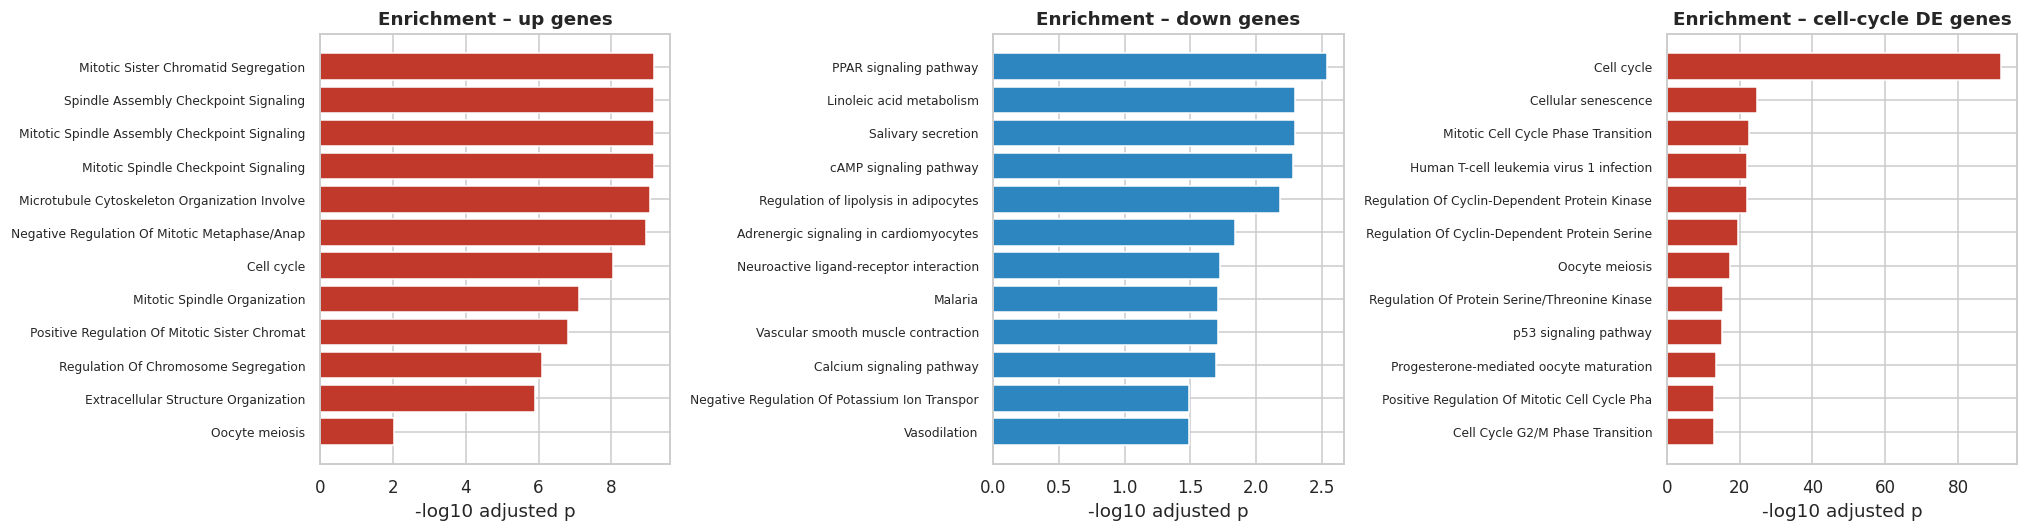

In [23]:
if enr:
    fig, axes = plt.subplots(1, len(enr), figsize=(6.2 * len(enr), 5))
    axes = np.atleast_1d(axes)
    for ax, (name, df_) in zip(axes, enr.items()):
        top = df_[df_.library.str.startswith(("GO", "KEGG"))].sort_values("adj_p").head(12).iloc[::-1]
        lab = top.term.str.replace(r" \(GO:\d+\)", "", regex=True).str.slice(0, 45)
        ax.barh(lab, -np.log10(top.adj_p), color=COL["Tumour"] if name != "down" else COL["Normal"])
        ax.set(title=f"Enrichment – {name} genes", xlabel="-log10 adjusted p"); ax.tick_params(axis="y", labelsize=8)
    plt.tight_layout(); plt.show()

### 6.2 STRING protein–protein interaction network
Significant cell-cycle genes (both directions) are submitted to the STRING API (v12, *Homo sapiens*, high-confidence edges, combined score ≥ 0.7). The network is analysed in NetworkX: node colour = log2 fold change, node size = degree; hubs are ranked by degree and betweenness centrality, and modules are found with Louvain community detection.

In [24]:
def string_network(genes, score=700):
    r = requests.post("https://string-db.org/api/tsv/network",
                      data={"identifiers": "\r".join(genes), "species": 9606, "required_score": score,
                            "caller_identity": "strathmore_bioinformatics_project"}, timeout=60)
    r.raise_for_status()
    return pd.read_csv(io.StringIO(r.text), sep="\t")

net_genes = cc_sig if len(cc_sig) >= 5 else list(cc_de.nsmallest(40, "p_wilcoxon").index)
G = None
try:
    edges = string_network(net_genes)
    edges = edges.drop_duplicates(["preferredName_A", "preferredName_B"])
    G = nx.Graph()
    G.add_nodes_from(net_genes)
    for _, e in edges.iterrows():
        G.add_edge(e.preferredName_A, e.preferredName_B, weight=e.score)
    edges.to_csv(f"{RES_DIR}/string_edges.csv", index=False)
    print(f"STRING network: {G.number_of_nodes()} nodes, {G.number_of_edges()} edges (score >= 0.7), "
          f"density {nx.density(G):.3f}, isolated nodes {nx.number_of_isolates(G)}")
except Exception as e:
    print(f"STRING API not reachable ({type(e).__name__}); network section skipped.")

STRING network: 54 nodes, 460 edges (score >= 0.7), density 0.321, isolated nodes 2


Largest connected component: 52 genes; Louvain communities: 3


,degree,betweenness,log2FC,community
CDK1,41,0.083,2.200,0.0
CCNA2,40,0.085,2.819,2.0
CCNB1,33,0.044,2.812,0.0
CDC45,33,0.035,3.667,1.0
CDC6,31,0.029,3.279,1.0
PCNA,29,0.059,1.046,2.0
CCNB2,28,0.025,3.195,0.0
CHEK1,28,0.021,2.011,1.0
PLK1,27,0.019,3.342,0.0
CDC20,27,0.012,3.859,0.0


  community 0: 23 genes, mean log2FC +2.46: AURKB, BUB1, BUB1B, CCNB1, CCNB2, CDC14A, CDC20, CDC25C, CDCA5, CDK1, DDX11, ESCO2, ESPL1, GADD45B, MAD2L1, NDC80, PKMYT1, PLK1, PTTG1, SFN, SMC1B, TRIP13, TTK
  community 1: 15 genes, mean log2FC +1.98: CDC45, CDC6, CDC7, CDT1, CHEK1, CHEK2, DBF4, DBF4B, MCM2, MCM4, MCM6, MCM7, ORC1, ORC6, PRKDC
  community 2: 14 genes, mean log2FC +0.99: CCNA1, CCNA2, CCND2, CCNE1, CCNE2, CDC25A, CDKN1C, CDKN2A, CDKN2B, E2F1, E2F2, E2F3, E2F5, PCNA


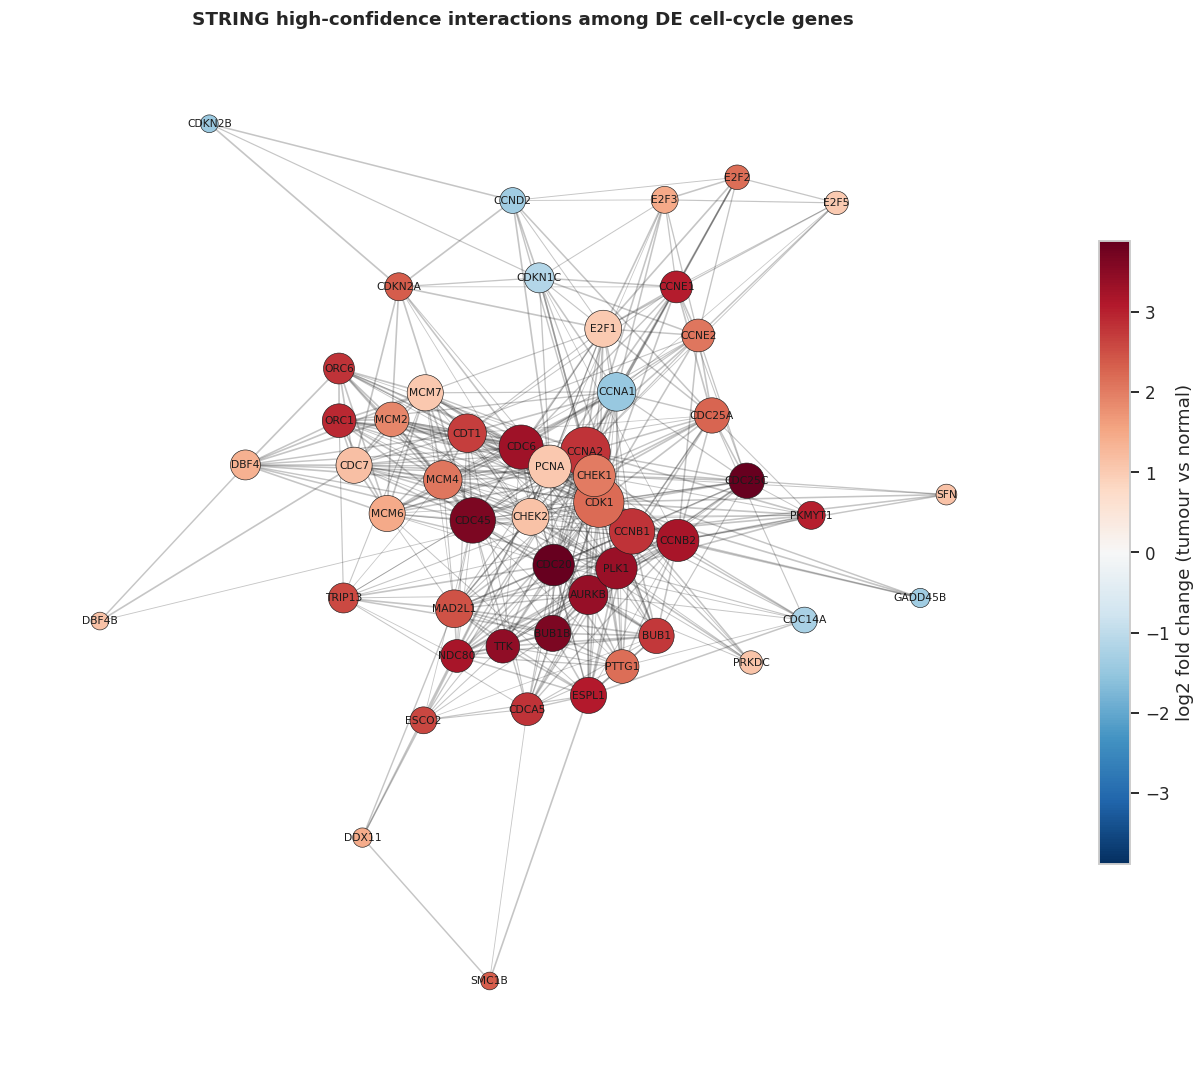

In [25]:
if G is not None and G.number_of_edges() > 0:
    Gc = G.subgraph(max(nx.connected_components(G), key=len)).copy()
    deg = dict(G.degree()); btw = nx.betweenness_centrality(G, weight=None)
    comms = nx.community.louvain_communities(Gc, seed=SEED)
    comm_of = {g: i for i, c in enumerate(sorted(comms, key=len, reverse=True)) for g in c}
    hubs = pd.DataFrame({"degree": deg, "betweenness": btw}).join(de["log2FC"]).assign(
        community=lambda x: x.index.map(comm_of)).sort_values(["degree", "betweenness"], ascending=False)
    hubs.round(3).to_csv(f"{RES_DIR}/string_hubs.csv")
    print(f"Largest connected component: {Gc.number_of_nodes()} genes; Louvain communities: {len(comms)}")
    display(hubs.head(15).round(3))
    for i, c in enumerate(sorted(comms, key=len, reverse=True)[:4]):
        fc = de.loc[[g for g in c if g in de.index], "log2FC"].mean()
        print(f"  community {i}: {len(c)} genes, mean log2FC {fc:+.2f}: {', '.join(sorted(c))}")

    fig, ax = plt.subplots(figsize=(12, 10))
    pos = nx.spring_layout(Gc, seed=SEED, k=0.45, weight="weight")
    fcs = np.array([de.at[g, "log2FC"] if g in de.index else 0 for g in Gc.nodes])
    vmax = np.abs(fcs).max()
    nx.draw_networkx_edges(Gc, pos, ax=ax, alpha=.25, width=[.5 + 2 * (Gc[u][v]["weight"] - .7) for u, v in Gc.edges])
    nodes = nx.draw_networkx_nodes(Gc, pos, ax=ax, node_color=fcs, cmap="RdBu_r", vmin=-vmax, vmax=vmax,
                                   node_size=[60 + 25 * deg[g] for g in Gc.nodes], edgecolors="k", linewidths=.4)
    nx.draw_networkx_labels(Gc, pos, ax=ax, font_size=7)
    plt.colorbar(nodes, ax=ax, shrink=.6, label="log2 fold change (tumour vs normal)")
    ax.set_title("STRING high-confidence interactions among DE cell-cycle genes"); ax.axis("off")
    plt.tight_layout(); plt.show()

**Interpretation (biological).** _To be completed from the outputs above._

## 7. Machine learning: can cell-cycle genes alone classify tumour vs normal?

**Design**
* Samples: all primary tumours and all normal samples after QC (not just the pairs). Label 1 = tumour.
* Features: the expressed KEGG cell-cycle genes only (log2 values), standardised **inside** each training fold.
* **Patient-grouped, stratified 5-fold cross-validation, repeated 3 times** (`StratifiedGroupKFold`): a patient's tumour and normal sample are never split across training and test, which prevents leakage through patient-specific expression.
* Class imbalance (≈9 tumours per normal) is handled with class weights, and we report **balanced accuracy, ROC-AUC, MCC and F1 for the minority (normal) class**; plain accuracy would be misleading.
* Models: L2-regularised logistic regression, random forest, RBF support-vector machine.
* Baselines: `DummyClassifier` (majority class and stratified random), a **label-permutation** null, and **random gene sets of the same size** (both uniformly random and matched to the expression level of the cell-cycle genes).

In [26]:
X = expr.loc[cc_genes].T.values
y = meta["label"].values
groups = meta["patient"].values
print(f"X: {X.shape[0]} samples x {X.shape[1]} cell-cycle genes; tumour {y.sum()}, normal {(y==0).sum()}")

SCORING = {"balanced_accuracy": "balanced_accuracy", "roc_auc": "roc_auc",
           "mcc": make_scorer(matthews_corrcoef), "f1_normal": make_scorer(f1_score, pos_label=0)}

def run_cv(model, X, y, groups, repeats=3, splits=5):
    out = []
    for r in range(repeats):
        cv = StratifiedGroupKFold(n_splits=splits, shuffle=True, random_state=SEED + r)
        res = cross_validate(model, X, y, groups=groups, cv=cv, scoring=SCORING, n_jobs=-1)
        out.append(pd.DataFrame({k[5:]: v for k, v in res.items() if k.startswith("test_")}))
    return pd.concat(out, ignore_index=True)

MODELS = {
    "Dummy (majority)": DummyClassifier(strategy="most_frequent"),
    "Dummy (stratified)": DummyClassifier(strategy="stratified", random_state=SEED),
    "Logistic regression": make_pipeline(StandardScaler(), LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000)),
    "Random forest": RandomForestClassifier(n_estimators=500, class_weight="balanced_subsample", random_state=SEED, n_jobs=-1),
    "SVM (RBF)": make_pipeline(StandardScaler(), SVC(C=1, gamma="scale", class_weight="balanced")),
}
cv_res = {name: run_cv(m, X, y, groups) for name, m in MODELS.items()}
summary = pd.DataFrame({n: r.mean() for n, r in cv_res.items()}).T
summary_sd = pd.DataFrame({n: r.std() for n, r in cv_res.items()}).T
table = summary.round(3).astype(str) + " ± " + summary_sd.round(3).astype(str)
display(table)
summary.round(4).to_csv(f"{RES_DIR}/ml_cv_summary.csv")

X: 574 samples x 152 cell-cycle genes; tumour 515, normal 59


,balanced_accuracy,roc_auc,mcc,f1_normal
Dummy (majority),0.5 ± 0.0,0.5 ± 0.0,0.0 ± 0.0,0.0 ± 0.0
Dummy (stratified),0.504 ± 0.043,0.504 ± 0.043,0.008 ± 0.087,0.106 ± 0.078
Logistic regression,0.988 ± 0.014,0.999 ± 0.002,0.947 ± 0.042,0.951 ± 0.041
Random forest,0.928 ± 0.065,0.993 ± 0.014,0.908 ± 0.083,0.912 ± 0.082
SVM (RBF),0.988 ± 0.014,0.999 ± 0.002,0.947 ± 0.042,0.951 ± 0.041


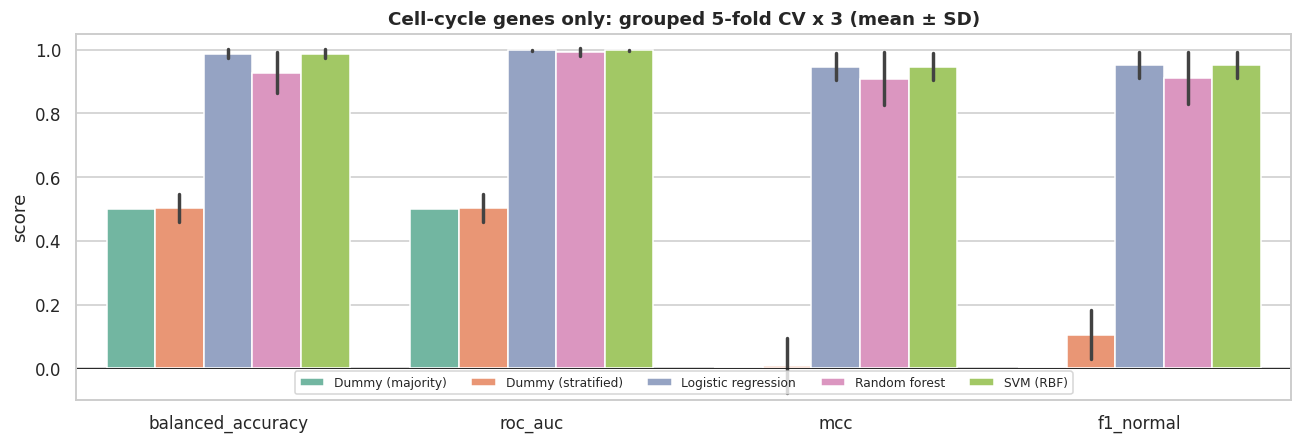

In [27]:
long = pd.concat([r.assign(model=n) for n, r in cv_res.items()]).melt(id_vars="model", var_name="metric")
plt.figure(figsize=(12, 4.2))
sns.barplot(data=long, x="metric", y="value", hue="model", errorbar="sd", palette="Set2")
plt.ylim(-0.1, 1.05); plt.axhline(0, c="k", lw=.6)
plt.title("Cell-cycle genes only: grouped 5-fold CV x 3 (mean ± SD)"); plt.ylabel("score"); plt.xlabel("")
plt.legend(fontsize=8, ncol=5, loc="lower center"); plt.tight_layout(); plt.show()

In [28]:
# Label-permutation null for logistic regression (is performance better than chance with the same pipeline?)
lr = MODELS["Logistic regression"]
cv1 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
def cv_scores(model, Xm, yy):
    r = cross_validate(model, Xm, yy, groups=groups, cv=cv1, scoring={k: SCORING[k] for k in ["balanced_accuracy", "roc_auc", "mcc"]}, n_jobs=-1)
    return {k: r[f"test_{k}"].mean() for k in ["balanced_accuracy", "roc_auc", "mcc"]}

obs_lr = cv_scores(lr, X, y)
perm = pd.DataFrame([cv_scores(lr, X, rng.permutation(y)) for _ in range(100)])
p_perm = {k: (1 + (perm[k] >= obs_lr[k]).sum()) / 101 for k in obs_lr}
print("Logistic regression (single 5-fold):", {k: round(v, 3) for k, v in obs_lr.items()})
print("Permuted labels, mean:", perm.mean().round(3).to_dict(), "| empirical p:", p_perm)

Logistic regression (single 5-fold): {'balanced_accuracy': np.float64(0.987), 'roc_auc': np.float64(0.999), 'mcc': np.float64(0.948)}
Permuted labels, mean: {'balanced_accuracy': 0.497, 'roc_auc': 0.492, 'mcc': -0.005} | empirical p: {'balanced_accuracy': np.float64(0.009900990099009901), 'roc_auc': np.float64(0.009900990099009901), 'mcc': np.float64(0.009900990099009901)}


balanced_accuracy        roc_auc         mcc       
                                mean    std    mean  std   mean    std
type                                                                  
expression-matched             0.995  0.003   0.999  0.0  0.964  0.008
uniform random                 0.995  0.003   1.000  0.0  0.964  0.010

uniform random: fraction of random sets scoring >= cell-cycle set -> balanced_accuracy 0.97, roc_auc 0.99, mcc 0.93
expression-matched: fraction of random sets scoring >= cell-cycle set -> balanced_accuracy 0.99, roc_auc 1.00, mcc 0.95


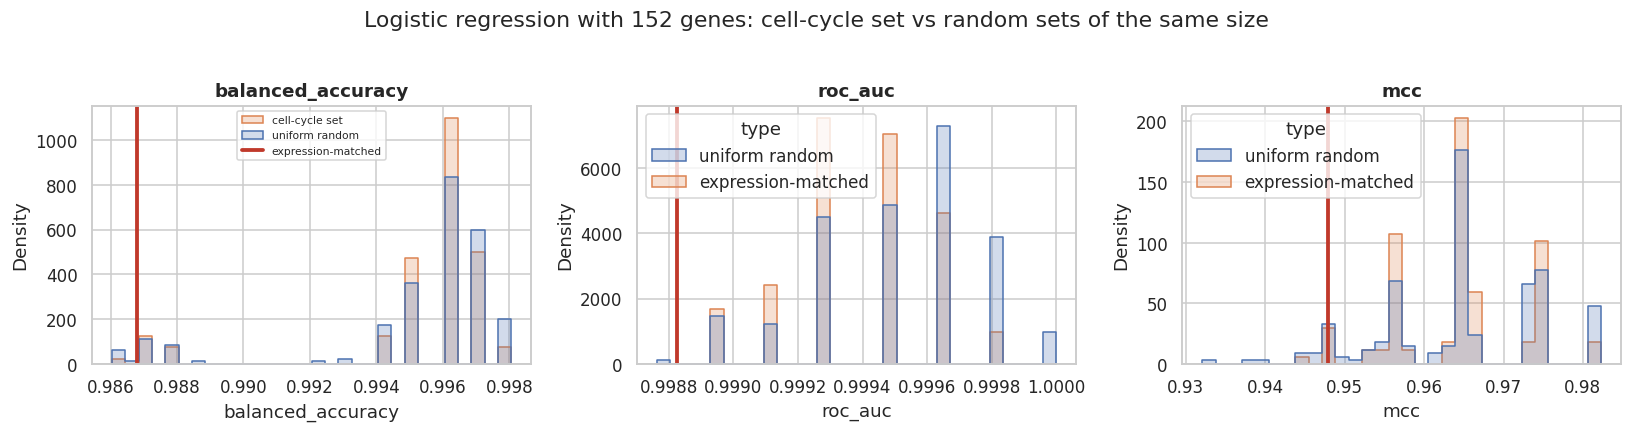

In [29]:
# Random gene sets of the same size: uniformly random, and matched on mean expression
non_cc = np.array([g for g in expr.index if g not in set(cc_genes)])
mean_e = expr.mean(1)
bins = pd.qcut(mean_e, 10, labels=False)
cc_bins = bins.loc[cc_genes].value_counts()

def random_set(matched):
    if not matched:
        return list(rng.choice(non_cc, len(cc_genes), replace=False))
    out = []
    for b, n_b in cc_bins.items():
        pool = np.setdiff1d(bins.index[bins == b], cc_genes)
        out += list(rng.choice(pool, n_b, replace=False))
    return out

N_RAND = 200
rand_rows = []
for matched in [False, True]:
    for i in range(N_RAND if not matched else N_RAND // 2):
        gs = random_set(matched)
        sc = cv_scores(lr, expr.loc[gs].T.values, y)
        rand_rows.append({**sc, "type": "expression-matched" if matched else "uniform random"})
rand = pd.DataFrame(rand_rows)
rand.to_csv(f"{RES_DIR}/random_geneset_ml.csv", index=False)

comp = rand.groupby("type").agg(["mean", "std"]).round(3)
display(comp)
for t in rand.type.unique():
    rr = rand[rand.type == t]
    print(f"{t}: fraction of random sets scoring >= cell-cycle set -> " +
          ", ".join(f"{k} {(rr[k] >= obs_lr[k]).mean():.2f}" for k in obs_lr))

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, k in zip(ax, ["balanced_accuracy", "roc_auc", "mcc"]):
    sns.histplot(data=rand, x=k, hue="type", bins=30, ax=a, element="step", stat="density", common_norm=False)
    a.axvline(obs_lr[k], c=COL["Tumour"], lw=2.5, label="cell-cycle set"); a.set_title(k)
ax[0].legend(["cell-cycle set", "uniform random", "expression-matched"], fontsize=7)
plt.suptitle(f"Logistic regression with {len(cc_genes)} genes: cell-cycle set vs random sets of the same size", y=1.03)
plt.tight_layout(); plt.show()

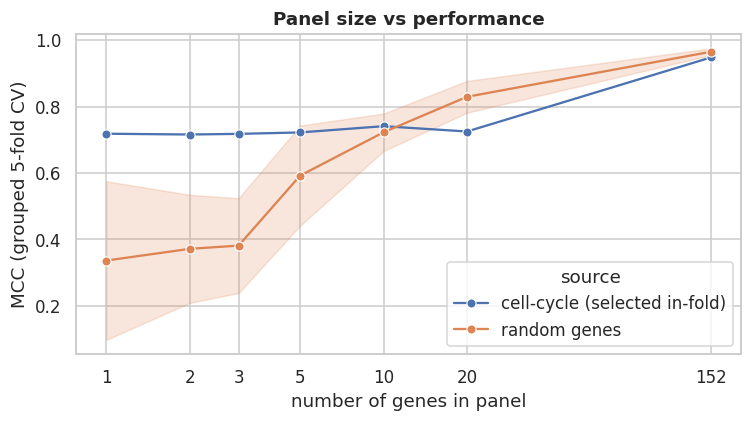

source,cell-cycle (selected in-fold),random genes
k,,
1,0.718,0.336
2,0.716,0.372
3,0.718,0.381
5,0.722,0.592
10,0.741,0.722
20,0.725,0.829
152,0.948,0.965


In [30]:
# How few cell-cycle genes are needed? (feature selection inside each training fold) vs random panels of the same size
ks = [1, 2, 3, 5, 10, 20, len(cc_genes)]
panel = []
for k in ks:
    m = make_pipeline(StandardScaler(), SelectKBest(f_classif, k=k), LogisticRegression(C=0.1, class_weight="balanced", max_iter=5000))
    panel.append({"k": k, "source": "cell-cycle (selected in-fold)", **cv_scores(m, X, y)})
    for _ in range(20):                                                       # random k-gene panels
        gs = rng.choice(non_cc, k, replace=False)
        panel.append({"k": k, "source": "random genes", **cv_scores(lr, expr.loc[gs].T.values, y)})
panel = pd.DataFrame(panel)
plt.figure(figsize=(7, 4))
sns.lineplot(data=panel, x="k", y="mcc", hue="source", marker="o", errorbar="sd")
plt.xscale("log"); plt.xticks(ks, ks); plt.ylabel("MCC (grouped 5-fold CV)"); plt.xlabel("number of genes in panel")
plt.title("Panel size vs performance"); plt.tight_layout(); plt.show()
display(panel.groupby(["source", "k"]).mean().round(3).unstack(0)["mcc"])

Logistic regression: balanced accuracy 1.000, MCC 1.000
Random forest: balanced accuracy 1.000, MCC 1.000


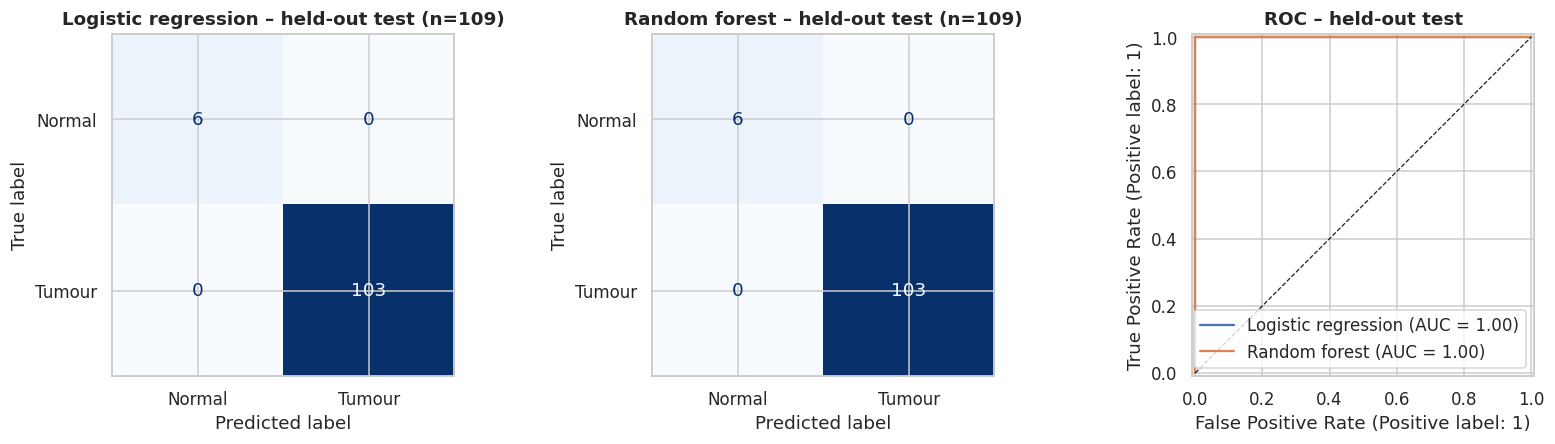

Out-of-fold misclassified: 6 / 574


,patient,group,pathologic_stage
sample,,,
TCGA-44-2657-11,TCGA-44-2657,Normal,Stage IB
TCGA-44-6148-01,TCGA-44-6148,Tumour,Stage IA
TCGA-75-6203-01,TCGA-75-6203,Tumour,Stage IIIA
TCGA-75-7030-01,TCGA-75-7030,Tumour,Stage IIB
TCGA-86-A4P8-01,TCGA-86-A4P8,Tumour,Stage IIIA
TCGA-L4-A4E6-01,TCGA-L4-A4E6,Tumour,Stage IA


In [31]:
# Held-out evaluation (one patient-grouped 80/20 split) + model inspection
train_idx, test_idx = next(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 100).split(X, y, groups))
assert not set(groups[train_idx]) & set(groups[test_idx]), "patient leakage!"
fig, ax = plt.subplots(1, 3, figsize=(15, 4.2))
for i, name in enumerate(["Logistic regression", "Random forest"]):
    mdl = MODELS[name].fit(X[train_idx], y[train_idx])
    pred = mdl.predict(X[test_idx])
    ConfusionMatrixDisplay(confusion_matrix(y[test_idx], pred), display_labels=["Normal", "Tumour"]).plot(ax=ax[i], colorbar=False, cmap="Blues")
    ax[i].set_title(f"{name} – held-out test (n={len(test_idx)})")
    RocCurveDisplay.from_estimator(mdl, X[test_idx], y[test_idx], ax=ax[2], name=name)
    print(f"{name}: balanced accuracy {balanced_accuracy_score(y[test_idx], pred):.3f}, MCC {matthews_corrcoef(y[test_idx], pred):.3f}")
ax[2].plot([0, 1], [0, 1], "k--", lw=.8); ax[2].set_title("ROC – held-out test")
plt.tight_layout(); plt.show()

# out-of-fold predictions: which samples are misclassified?
oof = cross_val_predict(MODELS["Logistic regression"], X, y, groups=groups, cv=cv1, method="predict")
mis = meta.assign(pred=oof)[oof != y]
print(f"Out-of-fold misclassified: {len(mis)} / {len(y)}")
display(mis[["patient", "group"] + [c for c in ["pathologic_stage"] if c in mis]].head(20))

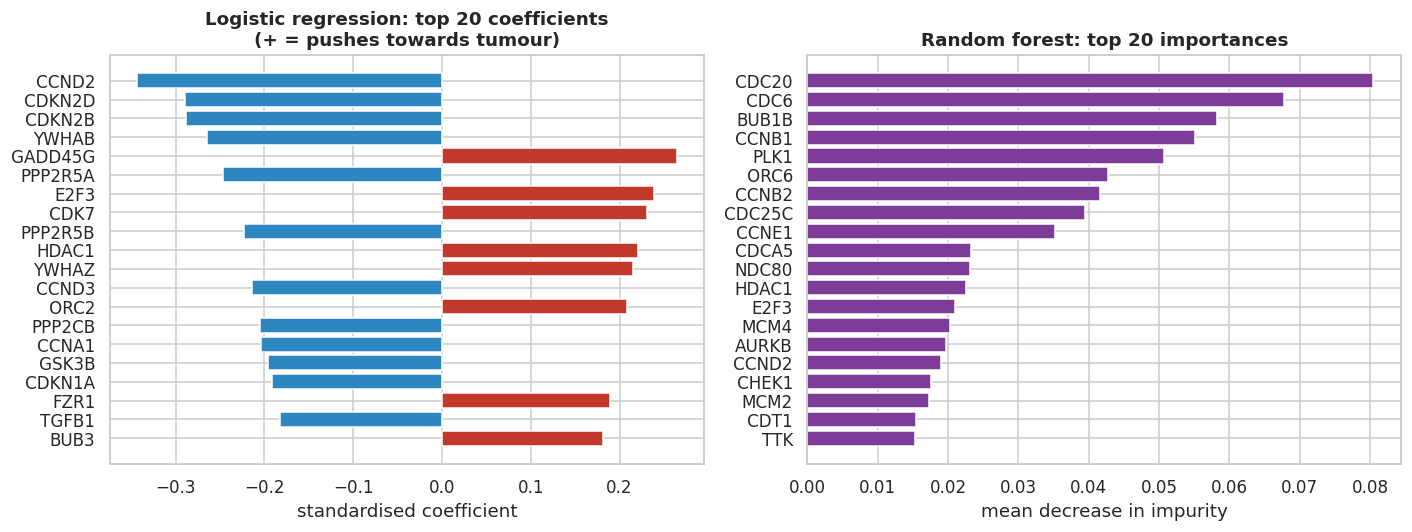

In [32]:
lr_full = MODELS["Logistic regression"].fit(X, y)
coef = pd.Series(lr_full[-1].coef_[0], index=cc_genes)
rf_full = MODELS["Random forest"].fit(X, y)
imp = pd.Series(rf_full.feature_importances_, index=cc_genes)
fig, ax = plt.subplots(1, 2, figsize=(13, 5))
top = coef.reindex(coef.abs().sort_values(ascending=False).index[:20]).iloc[::-1]
ax[0].barh(top.index, top.values, color=[COL["Tumour"] if v > 0 else COL["Normal"] for v in top.values])
ax[0].set(title="Logistic regression: top 20 coefficients\n(+ = pushes towards tumour)", xlabel="standardised coefficient")
ti = imp.sort_values().iloc[-20:]
ax[1].barh(ti.index, ti.values, color="#7D3C98"); ax[1].set(title="Random forest: top 20 importances", xlabel="mean decrease in impurity")
plt.tight_layout(); plt.show()

**Interpretation (machine learning).** _To be completed from the outputs above._

## 8. Conclusions
_To be completed from the results above._

In [33]:
# Key numbers in one place (for the conclusions and the presentation)
key = {
    "tumour samples": int(y.sum()), "normal samples": int((y == 0).sum()), "matched pairs": n_pairs,
    "expressed genes": len(expr), "KEGG cell-cycle genes analysed": len(cc_genes),
    "cell-cycle up (FDR<0.05, log2FC>=1)": int((cc_de.call == "Up").sum()),
    "cell-cycle down": int((cc_de.call == "Down").sum()),
    "KEGG set self-contained FDR": float(gset.loc["KEGG cell cycle (all)", "fdr_selfcontained_wilcoxon"]),
    "KEGG set competitive p (up)": float(gset.loc["KEGG cell cycle (all)", "p_competitive_up"]),
    "cell-cycle fraction up vs genome": f"{cc_up/cc_n:.1%} vs {oth_up/oth_n:.1%} (Fisher p={p_fisher:.1e})",
    "LR balanced accuracy (CV)": round(summary.loc["Logistic regression", "balanced_accuracy"], 3),
    "LR ROC-AUC (CV)": round(summary.loc["Logistic regression", "roc_auc"], 3),
    "LR MCC (CV)": round(summary.loc["Logistic regression", "mcc"], 3),
    "random same-size sets MCC (mean)": round(rand[rand.type == "uniform random"]["mcc"].mean(), 3),
}
display(pd.Series(key, name="value").to_frame())

,value
tumour samples,515
normal samples,59
matched pairs,58
expressed genes,17944
KEGG cell-cycle genes analysed,152
"cell-cycle up (FDR<0.05, log2FC>=1)",47
cell-cycle down,7
KEGG set self-contained FDR,0.0
KEGG set competitive p (up),0.0001
cell-cycle fraction up vs genome,30.9% vs 9.4% (Fisher p=1.6e-13)
